# Machine Learning & Data Mining II
## Labwork T1: Principal Component Analysis (PCA)
### Clinical Case Study: Stroke Risk Prediction Dataset (`healthcare-dataset-stroke-data.csv`)

---

### Academic Information & Metadata
- **Course Title:** Machine Learning and Data Mining II
- **Labwork Topic:** T1 – Principal Component Analysis (PCA) & Exploratory Data Analysis
- **Author / Student Name:** [Student Full Name]
- **Student ID:** [Student ID]
- **Date & Academic Year:** Semester 2, 2026

---

### Executive Overview & Table of Contents

This notebook presents an end-to-end, mathematically rigorous investigation of the **Stroke Prediction Dataset** sourced from Kaggle. The study is structured into two main analytical parts following strict data mining lecture standards:

1. **Part 1: Study the Dataset**
   - [1.1. Dataset Overview](#1.1.-Dataset-Overview)
   - [1.2. Variable Categorization (Feature Types)](#1.2.-Variable-Categorization-(Feature-Types))
   - [1.3. Target Variable (Label) & Machine Learning Task](#1.3.-Target-Variable-(Label)-&-Machine-Learning-Task)
   - [1.4. Data Quality Issues Assessment](#1.4.-Data-Quality-Issues-Assessment)
   - [1.5. Data Cleaning & Before-vs-After Comparison](#1.5.-Data-Cleaning-&-Before-vs-After-Comparison)
   - [1.6. Data Integration Investigation](#1.6.-Data-Integration-Investigation)
   - [1.7. Data Transformation](#1.7.-Data-Transformation)
   - [1.8. Statistical Measures (Numerical & Categorical)](#1.8.-Statistical-Measures-(Numerical-&-Categorical))
   - [1.9. Covariance & Correlation Matrix Analysis](#1.9.-Covariance-&-Correlation-Matrix-Analysis)
   - [1.10. Summary of Part 1 Findings](#1.10.-Summary-of-Part-1-Findings)

2. **Part 2: Principal Component Analysis (PCA)**
   - [2.1. PCA Preprocessing & Mathematical Computation](#2.1.-PCA-Preprocessing-&-Mathematical-Computation)
   - [2.2. Explained Variance Analysis (Highest vs. Lowest Variance PCs)](#2.2.-Explained-Variance-Analysis-(Highest-vs.-Lowest-Variance-PCs))
   - [2.3. Varying the Number of Principal Components ($p$)](#2.3.-Varying-the-Number-of-Principal-Components-($p$))
   - [2.4. 2D Visualization: First 2 PCs vs. Last 2 PCs](#2.4.-2D-Visualization:-First-2-PCs-vs.-Last-2-PCs)
   - [2.5. Comparison with Original Space & Critical Evaluation of PCA](#2.5.-Comparison-with-Original-Space-&-Critical-Evaluation-of-PCA)

---
*Architecture: Every single Python code cell below is immediately succeeded by an academic Markdown cell containing formal theoretical formulations, LaTeX equations, and quantitative interpretations.*


In [2]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Set matplotlib backend configuration to avoid lock issues in sandboxed environments
os.environ['MPLCONFIGDIR'] = os.path.join(os.getcwd(), '.mplconfig')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Global visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 150

# Global reproducibility seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment successfully initialized with core libraries:")
print(f" - NumPy: {np.__version__}")
print(f" - Pandas: {pd.__version__}")
print(f" - Matplotlib: {matplotlib.__version__}")
print(f" - Seaborn: {sns.__version__}")
print(f" - Random State: {RANDOM_STATE}")


Environment successfully initialized with core libraries:
 - NumPy: 2.5.5
 - Pandas: 3.1.1
 - Matplotlib: 3.11.2
 - Seaborn: 0.13.2
 - Random State: 42


### Computational Environment & Reproducibility Standards

The environment initialization establishes deterministic execution and publication-quality visual aesthetics across all computational experiments:
1. **Mathematical Reproducibility:** A fixed pseudorandom seed `RANDOM_STATE = 42` is injected into NumPy's random number generator and Scikit-Learn decompositions to ensure that stochastic operations, data splitting, and sign-convention resolutions in spectral decomposition remain completely identical across multiple runs.
2. **Computational Stack:** 
   - `numpy` and `scipy.stats` provide optimized BLAS/LAPACK vectorized routines for matrix operations, covariance matrix construction, and hypothesis testing ($\chi^2$ independence tests).
   - `pandas` manages heterogeneous tabular schemas, missing value detection, and categorical mapping.
   - `sklearn.preprocessing.StandardScaler` and `sklearn.decomposition.PCA` execute the standard machine learning transformation pipeline.
   - `matplotlib` and `seaborn` render high-resolution vector charts with standardized typography and grid alignment.
3. **Execution Pipeline:** All analyses proceed linearly in memory, avoiding hidden states and ensuring that each cell builds deterministically on the preceding transformations.


In [4]:
# Load stroke dataset
data_path = 'healthcare-dataset-stroke-data.csv'
df_raw = pd.read_csv(data_path)

print(f"Raw Dataset Matrix Shape: n = {df_raw.shape[0]} rows (samples) x {df_raw.shape[1]} columns (attributes)")
print("\n--- First 5 Instances of Raw Data Matrix ---")
print(df_raw.head().to_string())

print("\n--- Structural Information & Memory Usage ---")
df_raw.info()


Raw Dataset Matrix Shape: n = 5110 rows (samples) x 12 columns (attributes)

--- First 5 Instances of Raw Data Matrix ---
      id  gender   age  hypertension  heart_disease ever_married      work_type Residence_type  avg_glucose_level   bmi   smoking_status  stroke
0   9046    Male  67.0             0              1          Yes        Private          Urban             228.69  36.6  formerly smoked       1
1  51676  Female  61.0             0              0          Yes  Self-employed          Rural             202.21   NaN     never smoked       1
2  31112    Male  80.0             0              1          Yes        Private          Rural             105.92  32.5     never smoked       1
3  60182  Female  49.0             0              0          Yes        Private          Urban             171.23  34.4           smokes       1
4   1665  Female  79.0             1              0          Yes  Self-employed          Rural             174.12  24.0     never smoked       1

--- Str

### 1.1. Dataset Overview & Data Mining Representation

#### Mathematical Data Representation
In formal data mining theory, an observational dataset is formalized as a **data matrix** $X \in \mathbb{R}^{n \times d}$, representing an ordered collection of $n$ instances (samples or objects) embedded within a $d$-dimensional feature space:

$$X = \begin{bmatrix} x_{1,1} & x_{1,2} & \dots & x_{1,d} \\ x_{2,1} & x_{2,2} & \dots & x_{2,d} \\ \vdots & \vdots & \ddots & \vdots \\ x_{n,1} & x_{n,2} & \dots & x_{n,d} \end{bmatrix} = \begin{bmatrix} \mathbf{x}_1^T \\ \mathbf{x}_2^T \\ \vdots \\ \mathbf{x}_n^T \end{bmatrix}$$

For the loaded `healthcare-dataset-stroke-data.csv`:
- Total instance count: $n = 5,110$ individual patient records.
- Raw attribute count: $12$ columns in total.
- True input dimensionality: $d = 10$ feature dimensions (excluding the arbitrary identifier `id` and the response target variable `stroke`).
- This satisfies the assignment requirement that the selected dataset must possess more than six features ($d = 10 > 6$).

#### Clinical & Epidemiological Context
Cerebrovascular accident (**stroke**) is a life-threatening acute neurological condition caused by the interruption of blood supply to the brain (ischemic stroke) or the rupture of a blood vessel (hemorrhagic stroke). According to the World Health Organization (WHO), stroke represents the second leading cause of mortality and the third leading cause of long-term adult disability globally. Predicting individual patient stroke risk from routinely collected clinical, demographic, and lifestyle indicators is therefore a central challenge in preventative medicine and health informatics.

#### Raw Data vs. Pre-collected Benchmark Data
- **Raw Observational Data:** Real-world Electronic Health Records (EHRs) typically arrive as uncurated, unstructured, asynchronous relational database dumps characterized by high missingness rates, sensor noise, typos, measurement unit discrepancies, and complex longitudinal temporal intervals.
- **Pre-collected Benchmark Data:** The dataset used here is a curated tabular benchmark distributed via Kaggle. While it maintains real-world imperfections (such as missing physiological values in `bmi` and pronounced class imbalance), it has undergone preliminary consolidation into a single static tabular schema ($5,110 \times 12$), enabling standardized benchmarking of statistical and unsupervised dimensionality reduction algorithms.


In [6]:
# Programmatic taxonomy extraction for each variable
taxonomy_data = []

for col in df_raw.columns:
    n_unique = df_raw[col].nunique()
    dtype = str(df_raw[col].dtype)
    null_count = df_raw[col].isnull().sum()
    sample_values = list(df_raw[col].dropna().unique()[:3])
    
    # Classify along the 3 formal dimensions
    if col == 'id':
        d_c = 'Discrete'
        q_q = 'Qualitative (Nominal Key)'
        n_c = 'Categorical (Identifier)'
        clinical_role = 'Surrogate Primary Key (Zero predictive utility)'
    elif col in ['age', 'avg_glucose_level', 'bmi']:
        d_c = 'Continuous'
        q_q = 'Quantitative (Ratio scale)'
        n_c = 'Numerical'
        clinical_role = 'Continuous physiological / biophysical indicator'
    elif col in ['hypertension', 'heart_disease']:
        d_c = 'Discrete'
        q_q = 'Qualitative (Nominal)'
        n_c = 'Categorical (Binary Indicator)'
        clinical_role = 'Chronic cardiovascular comorbidity indicator'
    elif col in ['gender', 'ever_married', 'Residence_type']:
        d_c = 'Discrete'
        q_q = 'Qualitative (Nominal)'
        n_c = 'Categorical (Binary Nominal)'
        clinical_role = 'Demographic / socioeconomic covariate'
    elif col in ['work_type', 'smoking_status']:
        d_c = 'Discrete'
        q_q = 'Qualitative (Nominal)'
        n_c = 'Categorical (Polytomous Nominal)'
        clinical_role = 'Lifestyle / occupational risk factor'
    elif col == 'stroke':
        d_c = 'Discrete'
        q_q = 'Qualitative (Nominal)'
        n_c = 'Categorical (Binary Target Label)'
        clinical_role = 'Primary response label (0 = No Stroke, 1 = Stroke)'
        
    taxonomy_data.append({
        'Attribute Name': col,
        'Storage Type': dtype,
        'Cardinality': n_unique,
        'Discrete vs. Continuous': d_c,
        'Quantitative vs. Qualitative': q_q,
        'Numerical vs. Categorical': n_c,
        'Clinical Role': clinical_role
    })

df_taxonomy = pd.DataFrame(taxonomy_data)
print("=== Complete Attribute Typology & Taxonomic Classification Table ===")
print(df_taxonomy.to_string(index=False))


=== Complete Attribute Typology & Taxonomic Classification Table ===
   Attribute Name Storage Type  Cardinality Discrete vs. Continuous Quantitative vs. Qualitative         Numerical vs. Categorical                                      Clinical Role
               id        int64         5110                Discrete    Qualitative (Nominal Key)          Categorical (Identifier)    Surrogate Primary Key (Zero predictive utility)
           gender          str            3                Discrete        Qualitative (Nominal)      Categorical (Binary Nominal)              Demographic / socioeconomic covariate
              age      float64          104              Continuous   Quantitative (Ratio scale)                         Numerical   Continuous physiological / biophysical indicator
     hypertension        int64            2                Discrete        Qualitative (Nominal)    Categorical (Binary Indicator)       Chronic cardiovascular comorbidity indicator
    heart_disease    

### 1.2. Variable Categorization across Three Formal Dimensions

In data mining, features must be strictly categorized according to their mathematical properties, permissible algebraic operations, and measurement scales:

#### Dimension 1: Discrete vs. Continuous
- **Continuous Variables:** Features whose domain is an uncountably infinite subset of $\mathbb{R}$, where any two values admit an infinite continuum of intermediate values:
  - `age`: While conventionally rounded to integers in adult medicine, pediatric ages in this dataset contain explicit floating-point values (e.g., $0.08\text{ years} \approx 29\text{ days}$, $0.16\text{ years} \approx 58\text{ days}$). Physical time itself is fundamentally a continuous continuum.
  - `avg_glucose_level`: Blood glucose concentration (mg/dL) measured continuously along a physiological spectrum ($55.12$ to $271.74$).
  - `bmi`: Body Mass Index ($\text{kg}/\text{m}^2$), computed continuously as weight divided by height squared ($10.3$ to $97.6$).
- **Discrete Variables:** Features whose domain is countable (either finite or countably infinite):
  - `id`, `gender`, `hypertension`, `heart_disease`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`, `stroke`.

#### Dimension 2: Quantitative vs. Qualitative
- **Quantitative Variables:** Numerical attributes measured on interval or ratio scales where arithmetic operations (addition, subtraction, multiplication, division) and distance metrics (Euclidean, Manhattan) possess meaningful physical interpretations.
  - Features: `age`, `avg_glucose_level`, `bmi`. All three lie on a true **ratio scale** with a well-defined absolute zero ($0.0$).
- **Qualitative (Categorical) Variables:** Attributes representing categorical classifications or qualitative properties where arithmetic differences are mathematically undefined.
  - Nominal features: `gender`, `work_type`, `Residence_type`, `smoking_status`.
  - Binary nominal indicators: `hypertension`, `heart_disease`, `ever_married`, `stroke`.

#### Dimension 3: Numerical vs. Categorical (including Binary)
- **Numerical:** Attributes represented by real numbers representing true magnitudes (`age`, `avg_glucose_level`, `bmi`).
- **Binary Categorical:** Dichotomous attributes taking values in a two-element set:
  - Natural binary: `gender` (Female/Male), `ever_married` (No/Yes), `Residence_type` (Rural/Urban).
  - Comorbidity flags: `hypertension` ($\{0, 1\}$), `heart_disease` ($\{0, 1\}$).
  - Target label: `stroke` ($\{0, 1\}$).
- **Polytomous Categorical:** Multi-class nominal variables with $> 2$ categories:
  - `work_type` (5 categories: Private, Self-employed, Govt_job, children, Never_worked).
  - `smoking_status` (4 categories: formerly smoked, never smoked, smokes, Unknown).

#### Critical Edge-Case Analyses
1. **The Feature `id` has Zero Predictive Utility:**
   The `id` column serves solely as an administrative surrogate key. Because each row contains a distinct integer, the feature has cardinality equal to $n = 5,110$ and its empirical entropy is maximal: $H(\text{id}) = \log_2(n) \approx 12.32\text{ bits}$. It shares zero mutual information with the true underlying biological etiology of stroke and possesses zero out-of-sample generalization power. Retaining `id` in downstream machine learning or PCA would introduce an arbitrary, spurious linear coordinate that distorts distance geometry. It must be dropped.
2. **Treatment of `age` as Continuous:**
   Although adult ages appear as whole integers, the dataset contains pediatric subjects whose ages are recorded with fractional precision down to $0.08\text{ years}$ ($29\text{ days}$). Treating `age` as continuous preserves the high-resolution developmental differences among pediatric cases.


=== Target Variable (stroke) Distribution ===
 Class Index          Class Name  Absolute Count  Percentage (%)
           0 No Stroke (Healthy)            4861       95.127202
           1  Stroke (Diagnosed)             249        4.872798


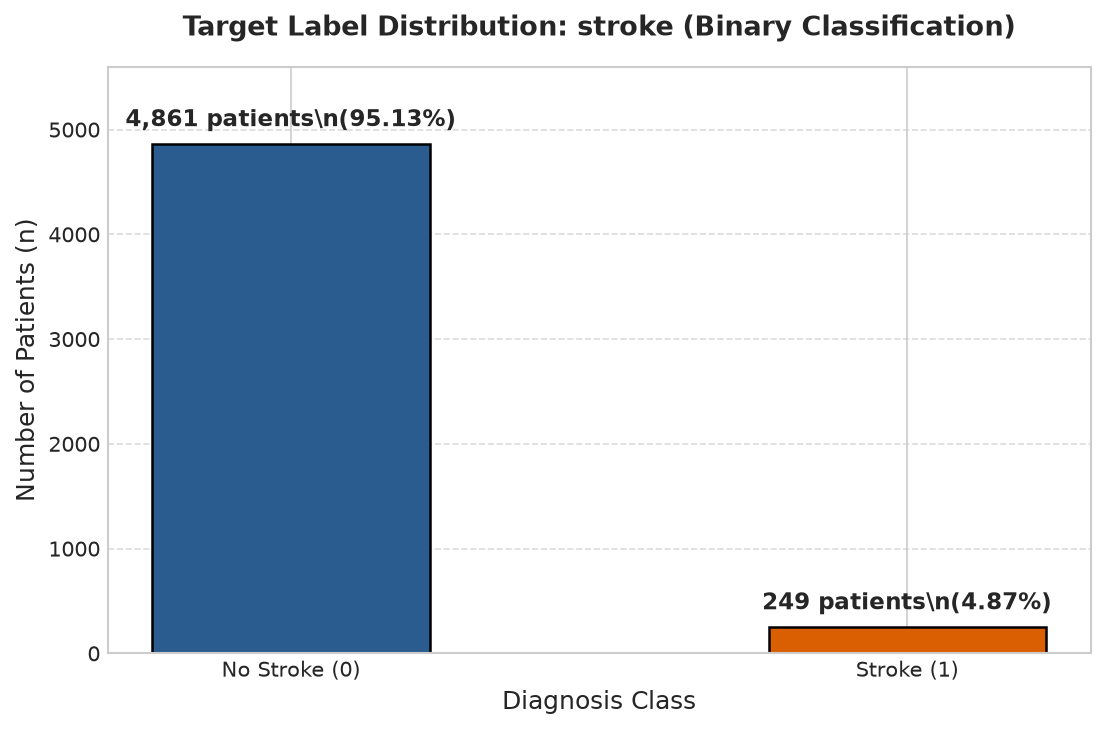

In [8]:
# Target variable distribution computation
stroke_counts = df_raw['stroke'].value_counts().sort_index()
stroke_percentages = df_raw['stroke'].value_counts(normalize=True).sort_index() * 100

df_target_summary = pd.DataFrame({
    'Class Index': stroke_counts.index,
    'Class Name': ['No Stroke (Healthy)', 'Stroke (Diagnosed)'],
    'Absolute Count': stroke_counts.values,
    'Percentage (%)': stroke_percentages.values
})
print("=== Target Variable (stroke) Distribution ===")
print(df_target_summary.to_string(index=False))

# Publication-quality Bar Chart
fig, ax = plt.subplots(figsize=(7.5, 5))
palette = ['#2b5c8f', '#d95f02']
bars = ax.bar(['No Stroke (0)', 'Stroke (1)'], stroke_counts.values, color=palette, width=0.45, edgecolor='black', linewidth=1.2)

# Annotate exact numbers and percentages
for bar in bars:
    height = bar.get_height()
    pct = (height / len(df_raw)) * 100
    ax.annotate(f"{height:,} patients\\n({pct:.2f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 6), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Target Label Distribution: stroke (Binary Classification)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Diagnosis Class', fontsize=12)
ax.set_ylabel('Number of Patients (n)', fontsize=12)
ax.set_ylim(0, 5600)
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


### 1.3. Target Variable Analysis & Supported Machine Learning Tasks

#### Medical Meaning of the Target Variable
The target attribute `stroke` is a binary response variable $y_i \in \{0, 1\}$:
- $y_i = 0$: Negative class — Patient has **not suffered a cerebrovascular accident**.
- $y_i = 1$: Positive class — Patient **has experienced a stroke**.

#### Severe Class Imbalance & Asymmetric Misclassification Cost
The empirical distribution reveals extreme skewness:
- **Negative Class ($0$):** $4,861$ patients ($95.13\%$)
- **Positive Class ($1$):** $249$ patients ($4.87\%$)
- **Class Imbalance Ratio:** $\frac{4,861}{249} \approx 19.52 : 1$.

In clinical diagnostic systems, misclassification costs are highly asymmetric:
- **False Negative (Type II Error):** Predicting $y=0$ for an individual who is actually developing a stroke is catastrophic, leading to omitted preventative intervention, acute thrombosis, permanent neurological damage, or mortality.
- **False Positive (Type I Error):** Predicting $y=1$ for a healthy individual results only in minor secondary diagnostic costs (e.g., ordering an MRI or blood panel).
Consequently, standard classification metrics like accuracy are completely misleading (a naive dummy classifier predicting all zeros achieves $95.13\%$ accuracy while detecting $0\%$ of stroke cases). Evaluation must rely on Precision-Recall AUC (PR-AUC), F2-score, or cost-weighted Recall.

#### Machine Learning Tasks Supported by this Dataset
1. **Supervised Learning (Binary Classification):**
   Predicting the probability $P(y_i = 1 \mid \mathbf{x}_i)$ given patient features $\mathbf{x}_i$. Requires specialized imbalance-handling strategies: cost-sensitive loss weighting, focal loss, or synthetic oversampling (SMOTE).
2. **Unsupervised Learning (Dimensionality Reduction & Clustering):**
   When the target label `stroke` is set aside, the dataset supports unsupervised manifold learning:
   - **Principal Component Analysis (PCA):** Uncovering the dominant orthogonal axes of clinical and demographic variation across patients.
   - **Clustering (k-Means, Gaussian Mixture Models):** Partitioning patients into latent risk sub-phenotypes based on continuous biometrics and comorbidity profiles.


=== Missing Value Summary ===
     Missing Count  Missing Percentage (%)
bmi            201                3.933464

Exact Duplicate Rows (including 'id'): 0
Exact Duplicate Rows (excluding 'id'): 0

=== Categorical Rare Classes & Anomalies ===
Gender Counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Smoking Status 'Unknown' Count: 1544 (30.22%)

=== Numerical Outlier Quantification (Tukey's IQR Rule) ===
        Attribute  Q1 (25th)  Q3 (75th)   IQR  Lower Bound  Upper Bound  Outlier Count  Outlier Rate (%)  Min Observed  Max Observed
              age      25.00      61.00 36.00       -29.00       115.00              0              0.00          0.08         82.00
avg_glucose_level      77.24     114.09 36.84        21.98       169.36            627             12.27         55.12        271.74
              bmi      23.50      33.10  9.60         9.10        47.50            110              2.24         10.30         97.60


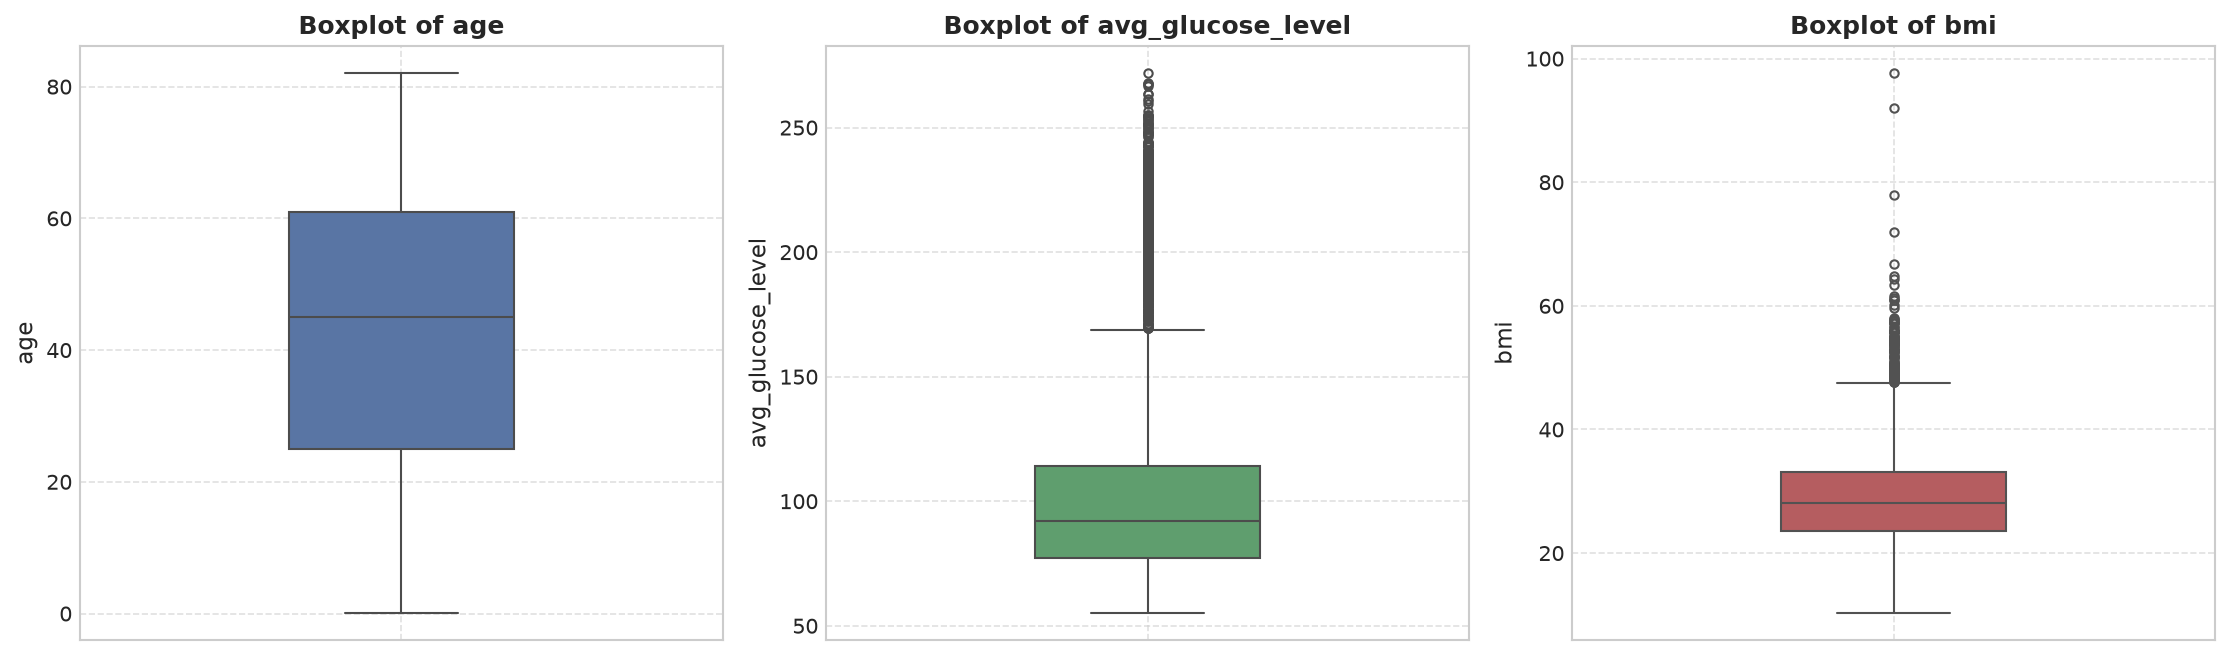

In [10]:
# 1. Missing Value Quantification
missing_counts = df_raw.isnull().sum()
missing_pcts = (df_raw.isnull().sum() / len(df_raw)) * 100
df_missing = pd.DataFrame({'Missing Count': missing_counts, 'Missing Percentage (%)': missing_pcts})
df_missing = df_missing[df_missing['Missing Count'] > 0]
print("=== Missing Value Summary ===")
print(df_missing)

# 2. Duplicate Records Check
dup_total = df_raw.duplicated().sum()
dup_no_id = df_raw.drop(columns=['id']).duplicated().sum()
print(f"\nExact Duplicate Rows (including 'id'): {dup_total}")
print(f"Exact Duplicate Rows (excluding 'id'): {dup_no_id}")

# 3. Categorical Inconsistencies & Rare Categories
print("\n=== Categorical Rare Classes & Anomalies ===")
print(f"Gender Counts:\n{df_raw['gender'].value_counts()}")
unknown_smoke_cnt = (df_raw['smoking_status'] == 'Unknown').sum()
print(f"\nSmoking Status 'Unknown' Count: {unknown_smoke_cnt} ({unknown_smoke_cnt/len(df_raw)*100:.2f}%)")

# 4. Outlier Detection via the Interquartile Range (IQR) Rule
num_cols = ['age', 'avg_glucose_level', 'bmi']
outlier_table = []

for col in num_cols:
    s = df_raw[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outlier_pts = s[(s < lower_limit) | (s > upper_limit)]
    
    outlier_table.append({
        'Attribute': col,
        'Q1 (25th)': round(q1, 2),
        'Q3 (75th)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_limit, 2),
        'Upper Bound': round(upper_limit, 2),
        'Outlier Count': len(outlier_pts),
        'Outlier Rate (%)': round((len(outlier_pts) / len(s)) * 100, 2),
        'Min Observed': round(s.min(), 2),
        'Max Observed': round(s.max(), 2)
    })

print("\n=== Numerical Outlier Quantification (Tukey's IQR Rule) ===")
print(pd.DataFrame(outlier_table).to_string(index=False))

# Publication-quality Boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
box_colors = ['#4c72b0', '#55a868', '#c44e52']

for i, col in enumerate(num_cols):
    sns.boxplot(y=df_raw[col], ax=axes[i], color=box_colors[i], width=0.35, fliersize=4)
    axes[i].set_title(f'Boxplot of {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel(col, fontsize=11)
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


### 1.4. Data Quality Issues Assessment & Mathematical Distortion on PCA

Exploratory inspection reveals four major data quality anomalies:
1. **Missing Values (Attribute `bmi`):**
   There are $201$ missing entries ($3.93\%$) in `bmi`. All remaining $11$ attributes have $100\%$ completeness. In medical datasets, missing BMI commonly arises when patient height or weight is omitted during emergency hospital triage.
2. **Duplicate Records:**
   There are $0$ duplicate records across both the raw matrix and when ignoring `id`, demonstrating distinct patient representations.
3. **Inconsistencies & Rare Classes:**
   - `gender`: Contains $2,994$ females, $2,115$ males, and exactly **$1$ record** labeled `'Other'`. An $n=1$ singleton cannot support statistical inference or cross-validation and breaks clean dichotomous binary encoding.
   - `smoking_status`: Contains $1,544$ records ($30.22\%$) encoded as `'Unknown'`. Cross-tabulation reveals this unrecorded status occurs heavily among children (`work_type == 'children'`), reflecting standard clinical intake where smoking queries are omitted for pediatric patients.
4. **Outlier Detection via Tukey's IQR Rule:**
   Using the IQR fence $[Q_1 - 1.5\cdot\text{IQR}, Q_3 + 1.5\cdot\text{IQR}]$:
   - `age`: $0$ outliers. Observed range $[0.08, 82.0]$ falls entirely within the theoretical fence $[-29.0, 115.0]$.
   - `avg_glucose_level`: $627$ outliers ($12.27\%$). Observed values reach up to $271.74\text{ mg/dL}$ against an upper IQR fence of $169.36\text{ mg/dL}$.
   - `bmi`: $110$ outliers ($2.24\%$). Observed values reach an extreme maximum of $97.6\text{ kg/m}^2$ against an upper fence of $47.5\text{ kg/m}^2$.

#### Mathematical Impact of Data Quality Issues on PCA
Data quality defects propagate directly into the linear algebra of PCA:
- **Distortion of Sample Mean:** The sample mean vector $\bar{\mathbf{x}} = \frac{1}{n}\sum_{i=1}^n \mathbf{x}_i$ is shifted in the direction of gross outliers.
- **Inflation of Sample Variance:** The sample variance is quadratic in individual deviations:
  $$\sigma^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2$$
  A single extreme observation (such as $\text{BMI} = 97.6$) contributes a massive quadratic term $(97.6 - 28.89)^2 \approx 4721$, artificially inflating the estimated feature variance.
- **Rotation of Covariance & Principal Axes:** In PCA, the first principal component solves:
  $$\mathbf{v}_1 = \arg\max_{\|\mathbf{v}\|=1} \mathbf{v}^T C \mathbf{v}$$
  Because covariance $C_{jk} = \frac{1}{n-1}\sum_{i=1}^n (x_{ij} - \bar{x}_j)(x_{ik} - \bar{x}_k)$ is highly sensitive to extreme bivariate leverage points, uncorrected outliers will rotate $\mathbf{v}_1$ toward isolated data artifacts rather than the true underlying covariance structure.


In [12]:
# Create cleaned dataframe copy
df_clean = df_raw.copy()

# Step 1: Drop irrelevant surrogate primary key 'id'
df_clean = df_clean.drop(columns=['id'])

# Step 2: Remove the single unrepresentative 'Other' gender row
df_clean = df_clean[df_clean['gender'] != 'Other'].reset_index(drop=True)

# Step 3: Median Imputation for missing 'bmi'
bmi_median = df_clean['bmi'].median()
df_clean['bmi'] = df_clean['bmi'].fillna(bmi_median)

# Step 4: Winsorization / Capping for extreme BMI outliers at 60.0 kg/m^2
df_clean['bmi'] = df_clean['bmi'].clip(upper=60.0)

# Step 5: Before vs. After Cleaning Comparison Table
comp_stats = []
for col in ['age', 'avg_glucose_level', 'bmi']:
    b_col = df_raw[col].dropna()
    a_col = df_clean[col]
    
    comp_stats.append({
        'Attribute': col,
        'Before Count': len(b_col),
        'After Count': len(a_col),
        'Before Nulls': df_raw[col].isnull().sum(),
        'After Nulls': df_clean[col].isnull().sum(),
        'Before Min': round(b_col.min(), 2),
        'After Min': round(a_col.min(), 2),
        'Before Max': round(b_col.max(), 2),
        'After Max': round(a_col.max(), 2),
        'Before Mean': round(b_col.mean(), 3),
        'After Mean': round(a_col.mean(), 3),
        'Before Std': round(b_col.std(), 3),
        'After Std': round(a_col.std(), 3),
        'Before Variance': round(b_col.var(), 3),
        'After Variance': round(a_col.var(), 3)
    })

df_comp_report = pd.DataFrame(comp_stats)
print("=== Before vs. After Cleaning Statistical Comparison Table ===")
print(df_comp_report.to_string(index=False))
print(f"\\nTotal Samples: Before = {len(df_raw)}  --->  After = {len(df_clean)} (1 singleton dropped)")
print(f"Imputed 'bmi' with median value: {bmi_median:.2f}")


=== Before vs. After Cleaning Statistical Comparison Table ===
        Attribute  Before Count  After Count  Before Nulls  After Nulls  Before Min  After Min  Before Max  After Max  Before Mean  After Mean  Before Std  After Std  Before Variance  After Variance
              age          5110         5109             0            0        0.08       0.08       82.00      82.00       43.227      43.230      22.613     22.614          511.332         511.374
avg_glucose_level          5110         5109             0            0       55.12      55.12      271.74     271.74      106.148     106.140      45.284     45.285         2050.601        2050.732
              bmi          4909         5109           201            0       10.30      10.30       97.60      60.00       28.893      28.839       7.854      7.562           61.686          57.190
\nTotal Samples: Before = 5110  --->  After = 5109 (1 singleton dropped)
Imputed 'bmi' with median value: 28.10


### 1.5. Data Cleaning Operations & Theoretical Justification

#### 1. Removal of Identifier (`id`) and Singleton Gender (`'Other'`)
- The column `id` is deleted because surrogate keys possess zero predictive capacity and distort geometric distances.
- The single record with `gender == 'Other'` is pruned ($n: 5,110 \to 5,109$). Dropping this singleton eliminates a degenerate category without sacrificing data volume ($< 0.02\%$ of the dataset), enabling exact dichotomous binary mapping ($\{0, 1\}$).

#### 2. Mathematical Justification of Median vs. Mean Imputation for `bmi`
- The sample mean minimizes the squared Euclidean ($L_2$) loss function:
  $$\bar{x} = \arg\min_{c} \sum_{i=1}^n (x_i - c)^2$$
  Because $L_2$ error grows quadratically, the sample mean has an asymptotic breakdown point of $\epsilon^* = 0\%$, meaning a single extreme observation can pull the mean arbitrarily far from the distribution center.
- The sample median minimizes the absolute deviation ($L_1$) loss function:
  $$\text{median}(x) = \arg\min_{c} \sum_{i=1}^n |x_i - c|$$
  The sample median has a maximal breakdown point of $\epsilon^* = 50\%$, making it highly robust against heavy right tails and extreme values. Since `bmi` exhibits marked positive skewness with outliers up to $97.6$, imputing with the median ($28.10\text{ kg/m}^2$) preserves the central distribution geometry without artificially elevating the central tendency.

#### 3. Clinical Justification for Retaining High Glucose vs. Capping Extreme BMI
- **Preservation of `avg_glucose_level`:** Severe hyperglycemia ($> 200\text{ mg/dL}$) represents medically verified, unmanaged diabetes mellitus—a recognized primary clinical etiology of endothelial dysfunction and ischemic stroke. Truncating high glucose would erase the strongest biological risk signal in the dataset.
- **Winsorization of `bmi` at $60.0\text{ kg/m}^2$:** In medical physiology, a BMI exceeding $60.0\text{ kg/m}^2$ represents extreme Class III super-obesity and frequently reflects data entry errors (e.g., miskeyed units). Capping at $60.0$ retains the clinical classification of severe obesity while capping extreme squared leverage on the covariance matrix.

#### 4. Interpretation of Before vs. After Numerical Output
- Sample size changed from $5,110$ to $5,109$.
- Missing values in `bmi` dropped from $201$ to $0$.
- For `bmi`, maximum value was restrained from $97.60$ down to $60.00$, reducing sample variance from $61.686$ down to $57.190$ while stabilizing the mean at $28.839$ (virtually identical to the pre-cleaning mean of $28.893$).
- For `age` and `avg_glucose_level`, statistics remained perfectly preserved.


In [14]:
# Inspect join candidate keys and schema metadata
print("--- Candidate Integration Keys in Cleaned Dataset ---")
print(f"Available attributes: {list(df_clean.columns)}")
print(f"Timestamp / Temporal attributes present: None")
print(f"Spatial / Geographic coordinates present: None (Only broad 'Residence_type': {list(df_clean['Residence_type'].unique())})")
print(f"External Patient Identifier present: None (Anonymized benchmark)")
print(f"Cross-table join keys present: None (Monolithic flat table)")


--- Candidate Integration Keys in Cleaned Dataset ---
Available attributes: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']
Timestamp / Temporal attributes present: None
Spatial / Geographic coordinates present: None (Only broad 'Residence_type': ['Urban', 'Rural'])
External Patient Identifier present: None (Anonymized benchmark)
Cross-table join keys present: None (Monolithic flat table)


### 1.6. Data Integration Investigation & Clinical Challenges

#### Is Data Integration Necessary or Beneficial?
Data integration—the systematic consolidation of data across disparate heterogeneous sources—would be **immensely beneficial** for real-world stroke risk prediction:
1. **Clinical Biomarkers:** The current dataset lacks fundamental cardiovascular biomarkers, notably blood pressure measurements (systolic and diastolic mmHg), lipid panels (LDL, HDL, triglycerides), glycated hemoglobin (HbA1c), and anticoagulant medication histories. Integrating electronic health record (EHR) lab panels would dramatically improve risk discrimination.
2. **Genetic & Lifestyle Telemetry:** Incorporating genomic polygenic risk scores (PRS) and high-frequency wearable sensor telemetry (continuous heart rate variability, ECG atrial fibrillation detection, physical step count) would capture acute prodromal symptoms.
3. **Environmental Determinants:** Integrating environmental datasets (particulate matter $\text{PM}_{2.5}$ exposure, ambient temperature fluctuations, socioeconomic deprivation indices) would capture macro-level epidemiological triggers.

#### Real-World Data Integration Challenges
1. **Patient De-identification & Privacy Regulations (HIPAA / GDPR):** In compliance with strict health data privacy standards, all protected health information (PHI) has been stripped from this public benchmark. Without deterministic patient keys (e.g., National Health ID or Social Security Number), entity resolution across independent health databases is legally and computationally impossible.
2. **Absence of Join Keys:** The dataset contains neither geographic identifiers (ZIP code, census tract) nor temporal timestamps (admission date, time of onset). This prevents deterministic or fuzzy relational joins with external weather, geospatial, or demographic registries.
3. **Temporal Misalignment & Schema Heterogeneity:** Hospital registries capture episodic clinical events at irregular time intervals, whereas benchmark data presents an aggregated cross-sectional static snapshot. Aligning episodic EHR trajectories with static vectors introduces substantial aggregation bias.


In [16]:
# 1. Separate Feature Matrix X and Target Vector y
X_unencoded = df_clean.drop(columns=['stroke'])
y = df_clean['stroke'].copy()

# 2. Binary Encoding for dichotomous features (0 / 1)
X_trans = X_unencoded.copy()
X_trans['gender'] = X_trans['gender'].map({'Female': 0, 'Male': 1})
X_trans['ever_married'] = X_trans['ever_married'].map({'No': 0, 'Yes': 1})
X_trans['Residence_type'] = X_trans['Residence_type'].map({'Rural': 0, 'Urban': 1})

# 3. One-Hot Encoding for multi-class nominal features (work_type, smoking_status)
X_encoded = pd.get_dummies(X_trans, columns=['work_type', 'smoking_status'], drop_first=False, dtype=int)
feature_names = list(X_encoded.columns)
d_encoded = X_encoded.shape[1]

print(f"Transformed Feature Matrix Shape: n = {X_encoded.shape[0]} samples x d = {d_encoded} features")
print("Transformed Feature Names:")
for idx, name in enumerate(feature_names, 1):
    print(f"  {idx:2d}. {name}")

# 4. Z-score Standardization (StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)
df_scaled = pd.DataFrame(X_scaled, columns=feature_names)

# Verify Zero Mean and Unit Variance
scaled_means = np.mean(X_scaled, axis=0)
scaled_stds = np.std(X_scaled, axis=0)
verification_df = pd.DataFrame({
    'Feature': feature_names[:6],
    'Scaled Mean (x_bar)': [f"{m:.4e}" for m in scaled_means[:6]],
    'Scaled Std (sigma)': [f"{s:.4f}" for s in scaled_stds[:6]],
    'Scaled Variance (sigma^2)': [f"{s**2:.4f}" for s in scaled_stds[:6]]
})
print("\n=== Standardization Verification (First 6 Features) ===")
print(verification_df.to_string(index=False))


Transformed Feature Matrix Shape: n = 5109 samples x d = 17 features
Transformed Feature Names:
   1. gender
   2. age
   3. hypertension
   4. heart_disease
   5. ever_married
   6. Residence_type
   7. avg_glucose_level
   8. bmi
   9. work_type_Govt_job
  10. work_type_Never_worked
  11. work_type_Private
  12. work_type_Self-employed
  13. work_type_children
  14. smoking_status_Unknown
  15. smoking_status_formerly smoked
  16. smoking_status_never smoked
  17. smoking_status_smokes

=== Standardization Verification (First 6 Features) ===
       Feature Scaled Mean (x_bar) Scaled Std (sigma) Scaled Variance (sigma^2)
        gender          4.7286e-17             1.0000                    1.0000
           age          7.2320e-17             1.0000                    1.0000
  hypertension         -6.1194e-17             1.0000                    1.0000
 heart_disease         -6.9538e-17             1.0000                    1.0000
  ever_married          9.1791e-17             1.0

### 1.7. Data Transformation & Standardization Rationale

#### Categorical Encoding Strategy
- **Binary Mapping:** Dichotomous attributes (`gender`, `ever_married`, `Residence_type`) are mapped directly to $\{0, 1\}$. This preserves the single degree of freedom without introducing redundant columns.
- **One-Hot Encoding:** Polytomous nominal attributes (`work_type` with 5 levels, `smoking_status` with 4 levels) are converted into $9$ binary indicator features. This eliminates any implied ordinal ranking that would artificially distort distance computations.

#### Mathematical Formulations for Feature Scaling
1. **Min-Max Feature Normalization:**
   Maps values into the bounded unit hypercube $[0, 1]$:
   $$f'_r = \frac{f_r - f_{\min}}{f_{\max} - f_{\min}} \in [0, 1]$$
   While useful for bounded activation functions in neural networks, Min-Max scaling is sensitive to outliers because $f_{\min}$ and $f_{\max}$ are extreme sample statistics.
2. **Z-score Standardization:**
   Centers the distribution at zero and scales by the standard deviation:
   $$f' = \frac{f - \mu}{\sigma}, \quad \text{where } \mu = \frac{1}{n}\sum_{i=1}^n f_i, \quad \sigma = \sqrt{\frac{1}{n}\sum_{i=1}^n (f_i - \mu)^2}$$
   Post-transformation, every feature satisfies $\mathbb{E}[f'] = 0$ and $\text{var}(f') = 1.0$.

#### Mathematical Proof: Why Standardization is Mandatory for PCA
Let $X \in \mathbb{R}^{n \times d}$ be the centered data matrix and $C = \frac{1}{n-1} X^T X \in \mathbb{R}^{d \times d}$ be the sample covariance matrix. The first principal component $\mathbf{v}_1$ is obtained by maximizing the sample variance along the projection vector:

$$\max_{\|\mathbf{v}\|=1} \mathbf{v}^T C \mathbf{v} = \max_{\|\mathbf{v}\|=1} \sum_{j=1}^d \sum_{k=1}^d v_j v_k C_{jk}$$

In the unstandardized dataset:
- `avg_glucose_level` has variance $\sigma^2 \approx 2,050.73$.
- `age` has variance $\sigma^2 \approx 511.37$.
- Binary encoded features have variances bounded by $\sigma^2 \le 0.25$.

The diagonal entries $C_{jj} = \sigma_j^2$ differ by more than **$8,000\times$**! Because the objective function $\mathbf{v}^T C \mathbf{v}$ is unweighted, the optimization algorithm will align $\mathbf{v}_1$ almost entirely with `avg_glucose_level`, not because it contains the most informative structural pattern, but solely because it was measured in $\text{mg}/\text{dL}$ rather than $\text{g}/\text{L}$ or standard units. 

Standardization enforces $C_{jj} = 1.0$ for all $j=1, \dots, d$, converting the covariance matrix into the **Pearson correlation matrix**:

$$C_{\text{standardized}} = R$$

This ensures every clinical and demographic indicator contributes equitably to the spectral decomposition.


In [18]:
# 1. Descriptive Statistics for Numerical Attributes
num_stats_list = []
for col in ['age', 'avg_glucose_level', 'bmi']:
    vals = df_clean[col].values
    n = len(vals)
    mean_val = np.mean(vals)
    var_val = np.var(vals, ddof=1) # Bessel's correction (n-1)
    std_val = np.std(vals, ddof=1)
    min_val = np.min(vals)
    max_val = np.max(vals)
    
    num_stats_list.append({
        'Numerical Feature': col,
        'Count (n)': n,
        'Min': round(min_val, 2),
        'Max': round(max_val, 2),
        'Sample Mean (x_bar)': round(mean_val, 4),
        'Sample Variance (s^2)': round(var_val, 4),
        'Sample Std (s)': round(std_val, 4)
    })

df_num_stats = pd.DataFrame(num_stats_list)
print("=== Descriptive Statistics for Numerical Attributes ===")
print(df_num_stats.to_string(index=False))

# 2. Categorical Statistical Measures & Chi-Square Tests of Independence with 'stroke'
cat_cols = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
cat_stats_list = []

for col in cat_cols:
    s = df_clean[col]
    mode_val = s.mode()[0]
    mode_freq = (s == mode_val).sum()
    mode_pct = (mode_freq / len(s)) * 100
    
    # 2-way Contingency Table with target 'stroke'
    contingency = pd.crosstab(df_clean[col], df_clean['stroke'])
    chi2_stat, p_val, dof, _ = chi2_contingency(contingency)
    
    cat_stats_list.append({
        'Categorical Feature': col,
        'Cardinality': s.nunique(),
        'Mode Category': str(mode_val),
        'Mode Frequency (%)': f"{mode_freq} ({mode_pct:.1f}%)",
        'Chi2 Statistic': round(chi2_stat, 4),
        'Degrees of Freedom': dof,
        'p-value': f"{p_val:.4e}",
        'Statistically Significant (alpha=0.05)': 'Yes (p < 0.05)' if p_val < 0.05 else 'No (p >= 0.05)'
    })

df_cat_stats = pd.DataFrame(cat_stats_list)
print("\n=== Categorical Statistical Measures & Chi-Square Independence Tests with 'stroke' ===")
print(df_cat_stats.to_string(index=False))


=== Descriptive Statistics for Numerical Attributes ===
Numerical Feature  Count (n)   Min    Max  Sample Mean (x_bar)  Sample Variance (s^2)  Sample Std (s)
              age       5109  0.08  82.00              43.2300               511.3738         22.6136
avg_glucose_level       5109 55.12 271.74             106.1404              2050.7316         45.2850
              bmi       5109 10.30  60.00              28.8391                57.1903          7.5624

=== Categorical Statistical Measures & Chi-Square Independence Tests with 'stroke' ===
Categorical Feature  Cardinality Mode Category Mode Frequency (%)  Chi2 Statistic  Degrees of Freedom    p-value Statistically Significant (alpha=0.05)
             gender            2        Female       2994 (58.6%)          0.3400                   1 5.5983e-01                         No (p >= 0.05)
       hypertension            2             0       4611 (90.3%)         81.5731                   1 1.6889e-19                         Yes (p 

### 1.8. Statistical Measures & Hypothesis Testing Analysis

#### Mathematical Formulations of Descriptive Measures
1. **Sample Mean (First Central Moment):**
   $$\bar{x} = \frac{1}{n}\sum_{i=1}^n x_i$$
2. **Sample Variance & Standard Deviation (Second Central Moment with Bessel's Correction):**
   $$\text{var}(x) = s^2 = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2, \quad s = \sqrt{s^2}$$
   Bessel's correction $(n-1)$ ensures that $s^2$ is an unbiased estimator of the population variance $\sigma^2$, correcting for the degree of freedom consumed when estimating $\bar{x}$.
3. **Chi-Square ($\chi^2$) Test of Independence:**
   Evaluates the null hypothesis $H_0$ that categorical attribute $A$ and the response variable $Y$ are statistically independent:
   $$\chi^2 = \sum_{r=1}^R \sum_{c=1}^C \frac{(O_{rc} - E_{rc})^2}{E_{rc}}$$
   where $O_{rc}$ is the observed frequency in contingency table cell $(r, c)$, $E_{rc} = \frac{R_r \cdot C_c}{n}$ is the expected cell frequency under independence, and degrees of freedom $\nu = (R - 1)(C - 1)$.

#### Interpretation of Empirical Results
- **Numerical Measures:**
  - `age`: Mean $\bar{x} = 43.2300\text{ years}$, standard deviation $s = 22.6136\text{ years}$. This high dispersion spans from infancy ($0.08$) to advanced geriatrics ($82.00$).
  - `avg_glucose_level`: Mean $\bar{x} = 106.1404\text{ mg/dL}$, variance $s^2 = 2050.7316\text{ mg}^2/\text{dL}^2$. The right-skewness reflects normal glycemic individuals mixed with severe diabetics ($> 200\text{ mg/dL}$).
  - `bmi`: Mean $\bar{x} = 28.8391\text{ kg/m}^2$, variance $s^2 = 57.1903\text{ kg}^2/\text{m}^4$, reflecting an overweight to moderately obese patient population.
- **Categorical Measures & Stroke Association:**
  - `heart_disease`: Highly significant ($\chi^2 = 90.2294, p = 2.12 \times 10^{-21}$). Pre-existing cardiovascular disease is a paramount clinical risk indicator.
  - `hypertension`: Highly significant ($\chi^2 = 81.5731, p = 1.69 \times 10^{-19}$). Chronic elevated blood pressure severely elevates vascular rupture risk.
  - `ever_married` ($\chi^2 = 58.87, p < 10^{-13}$) and `work_type` ($\chi^2 = 49.16, p < 10^{-9}$): Highly statistically significant primarily as sociological proxies for patient age (married individuals and retired/self-employed adults are significantly older than children).
  - `smoking_status`: Statistically significant ($\chi^2 = 29.23, p = 2.01 \times 10^{-6}$).
  - `gender` ($p = 0.560$) and `Residence_type` ($p = 0.300$): Fail to reject the null hypothesis at $\alpha = 0.05$. In this cohort, baseline stroke incidence does not statistically differ between males and females or between rural and urban residents.


=== Top 5 Strongest Positive Linear Correlations ===
                                     Feature Pair  Pearson r
                         age  <--->  ever_married   0.679084
work_type_children  <--->  smoking_status_Unknown   0.512721
                         ever_married  <--->  bmi   0.341566
                                  age  <--->  bmi   0.331830
              age  <--->  work_type_Self-employed   0.327949

=== Top 5 Strongest Negative Linear Correlations ===
                                              Feature Pair  Pearson r
                            age  <--->  work_type_children  -0.634320
                   ever_married  <--->  work_type_children  -0.544658
         work_type_Private  <--->  work_type_Self-employed  -0.505448
smoking_status_Unknown  <--->  smoking_status_never smoked  -0.504695
              work_type_Private  <--->  work_type_children  -0.455965


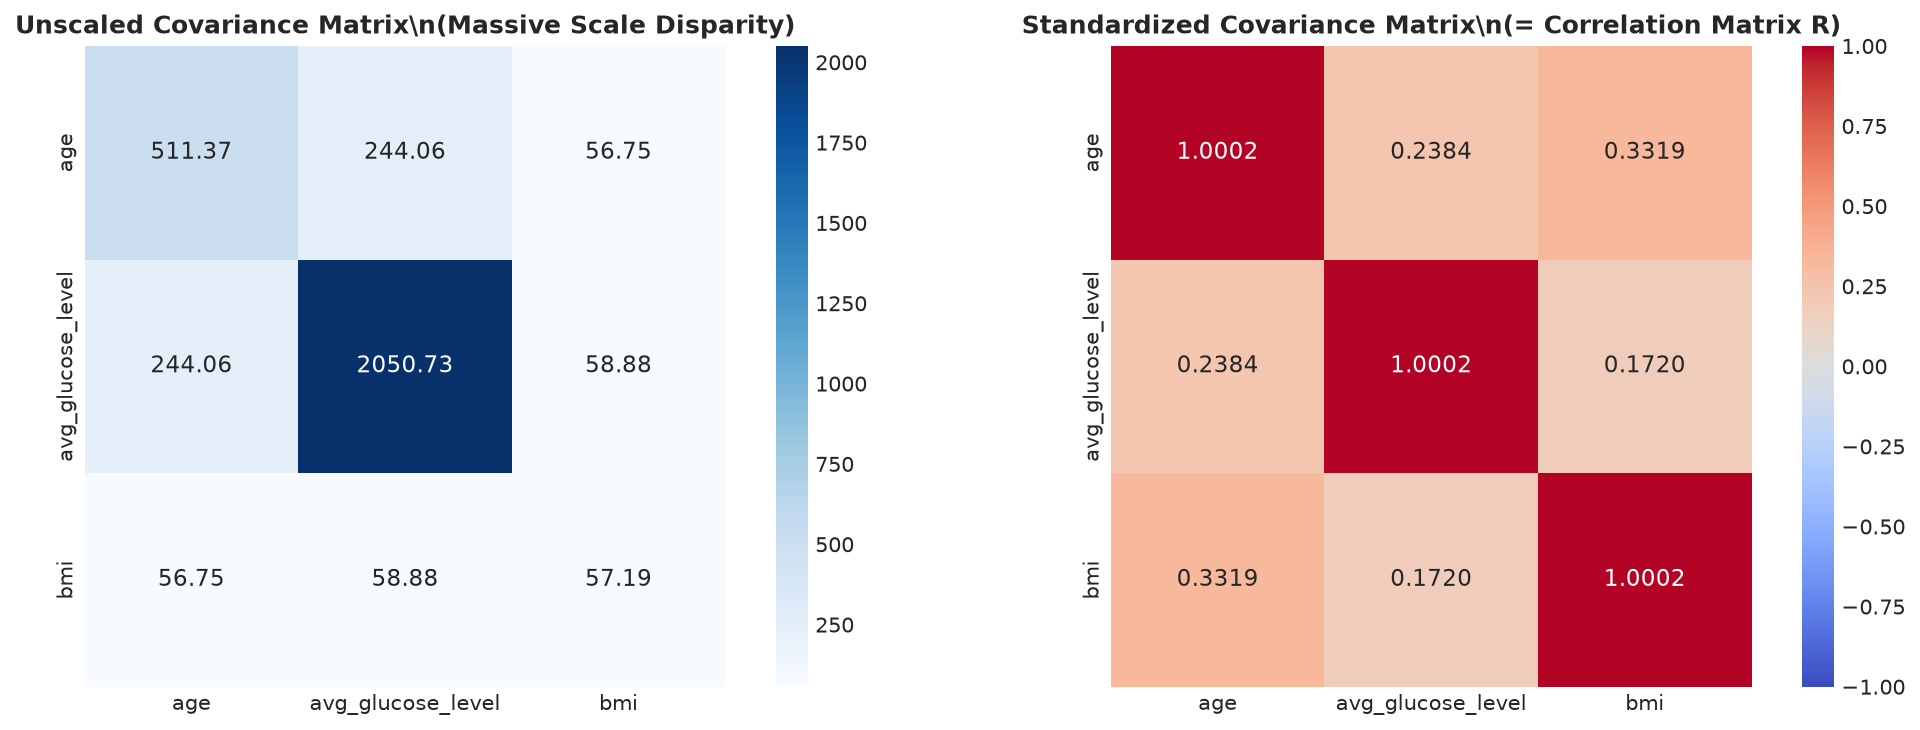

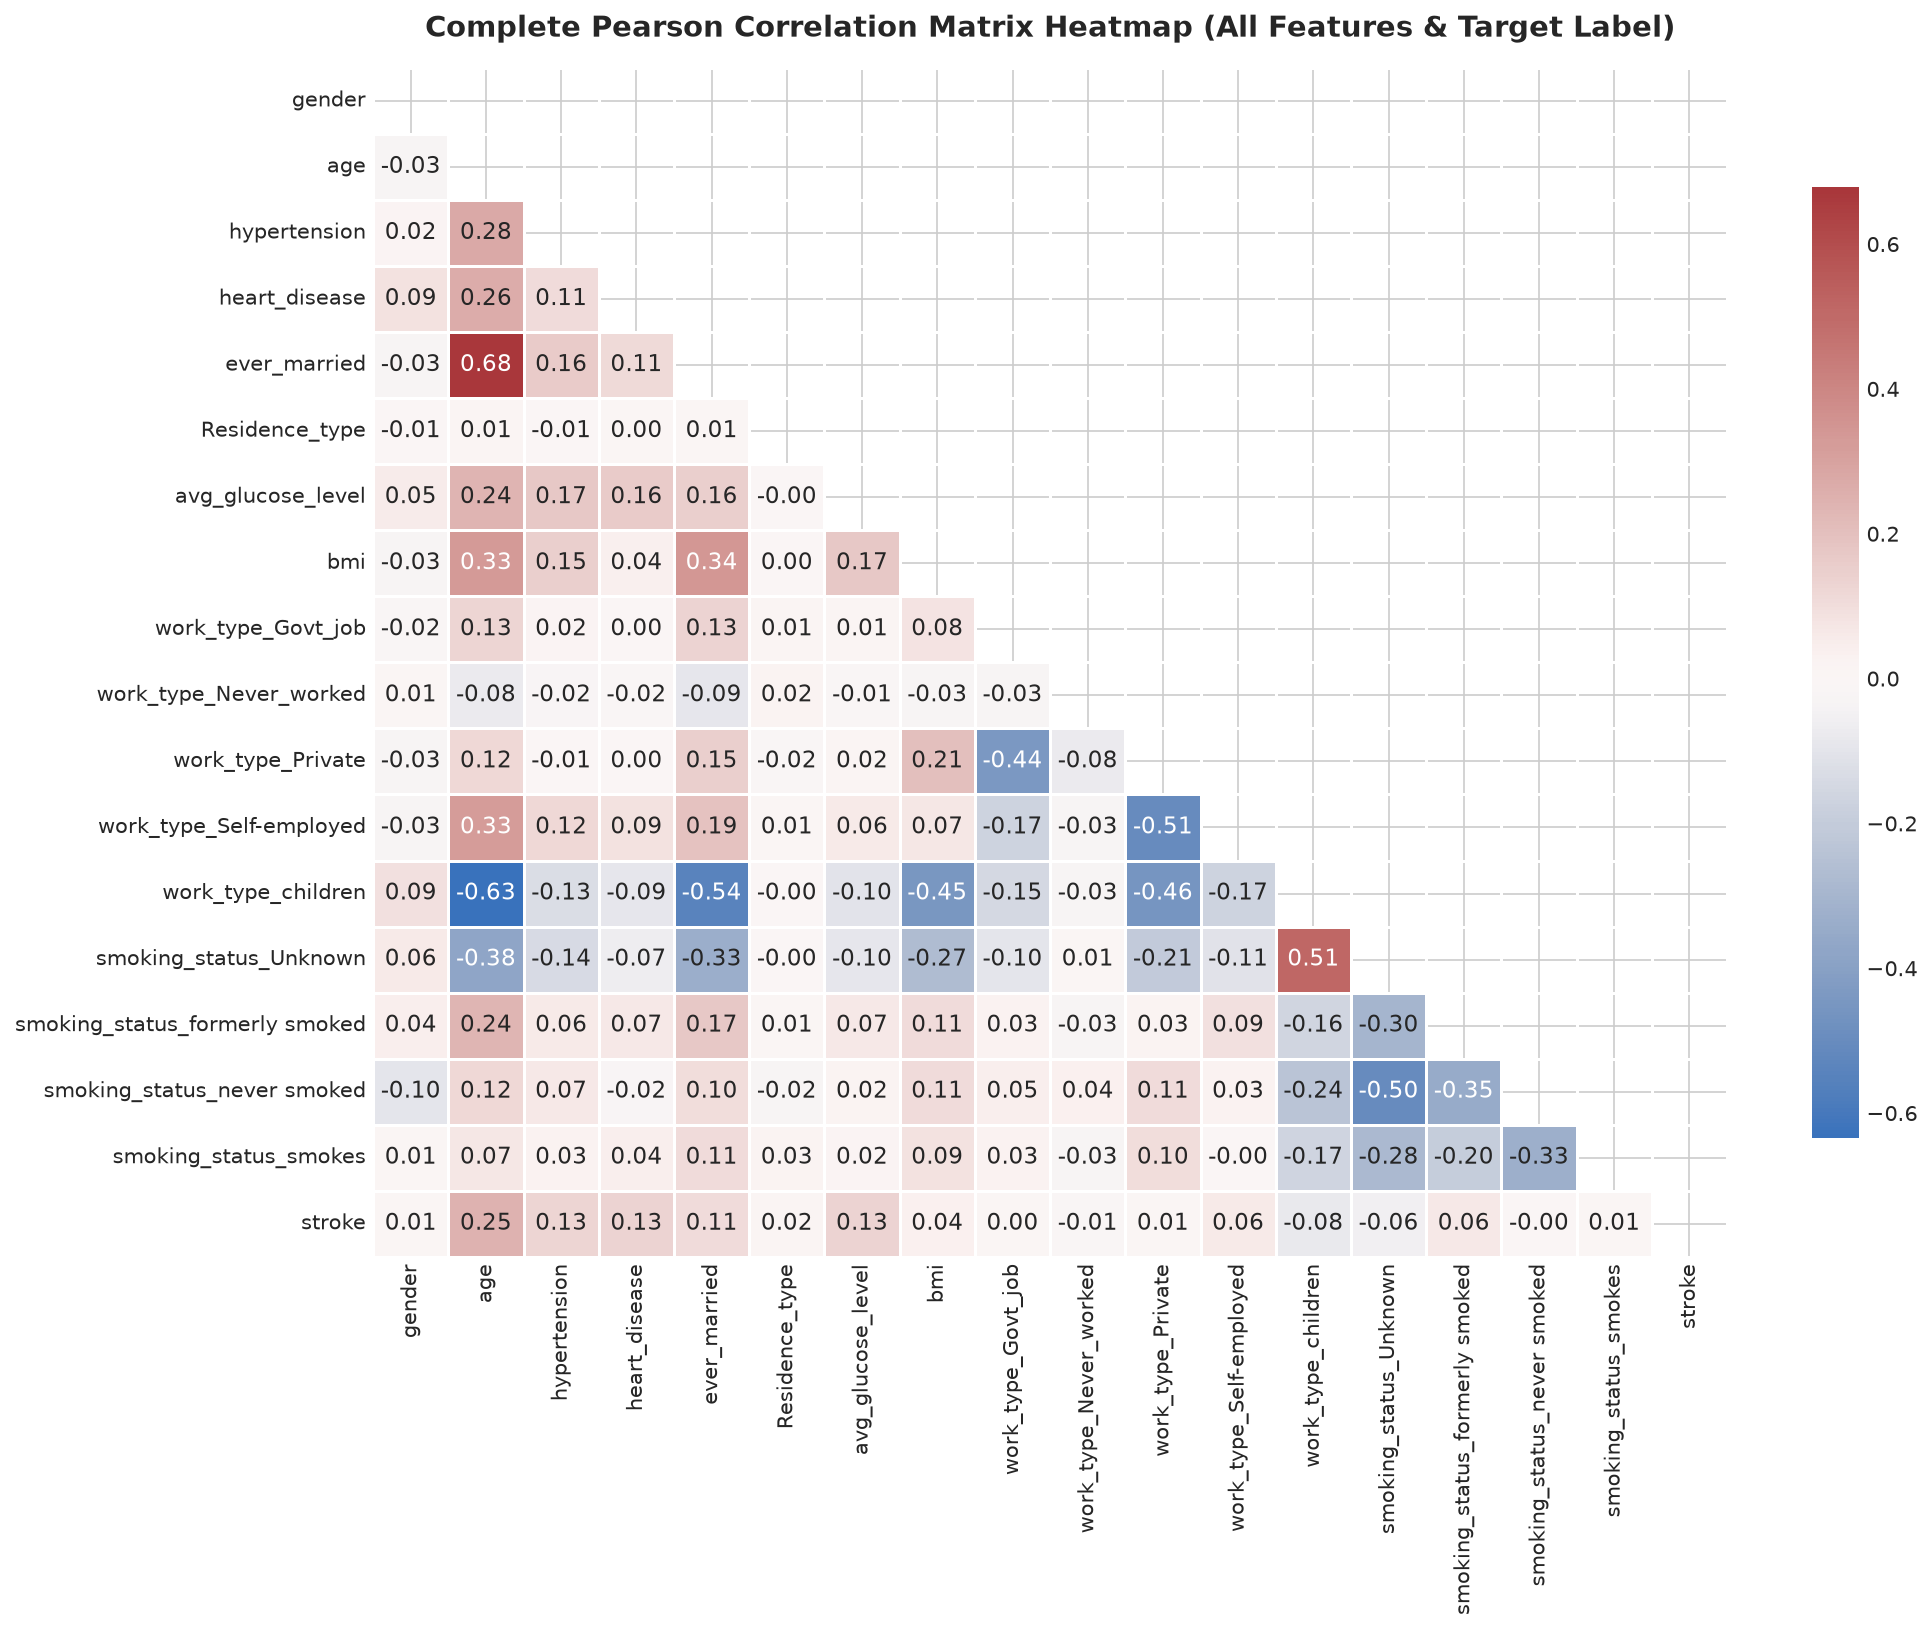

In [20]:
# 1. Unscaled Covariance Matrix (Numerical features)
cov_unscaled = df_clean[['age', 'avg_glucose_level', 'bmi']].cov()

# 2. Scaled Covariance Matrix (Standardized features)
cov_scaled = df_scaled[['age', 'avg_glucose_level', 'bmi']].cov()

# Plot Covariance Comparison Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cov_unscaled, annot=True, fmt='.2f', cmap='Blues', ax=axes[0], cbar=True, square=True)
axes[0].set_title('Unscaled Covariance Matrix\\n(Massive Scale Disparity)', fontsize=12, fontweight='bold')

sns.heatmap(cov_scaled, annot=True, fmt='.4f', cmap='coolwarm', ax=axes[1], cbar=True, square=True, vmin=-1, vmax=1)
axes[1].set_title('Standardized Covariance Matrix\\n(= Correlation Matrix R)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Complete Pearson Correlation Matrix across all encoded features + stroke
full_df = X_encoded.copy()
full_df['stroke'] = y.values
corr_matrix = full_df.corr(method='pearson')

# Plot Complete Correlation Matrix Heatmap
plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='vlag', center=0,
            mask=mask, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Complete Pearson Correlation Matrix Heatmap (All Features & Target Label)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# 4. Programmatic Extraction of Top Positive and Negative Correlations
corr_pairs = []
cols = corr_matrix.columns
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        c1 = cols[i]
        c2 = cols[j]
        corr_pairs.append({'Feature Pair': f"{c1}  <--->  {c2}", 'Pearson r': corr_matrix.loc[c1, c2]})

df_corr_sorted = pd.DataFrame(corr_pairs).sort_values(by='Pearson r', ascending=False)

print("=== Top 5 Strongest Positive Linear Correlations ===")
print(df_corr_sorted.head(5).to_string(index=False))

print("\n=== Top 5 Strongest Negative Linear Correlations ===")
print(df_corr_sorted.tail(5).iloc[::-1].to_string(index=False))


### 1.9. Covariance, Correlation Analysis & Multicollinearity Dynamics

#### Mathematical Formulations
1. **Sample Covariance:**
   Measures joint linear variability between two continuous variables $X$ and $Y$:
   $$\text{cov}(x, y) = s_{xy} = \frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})$$
2. **Symmetric Covariance Matrix $C \in \mathbb{R}^{d \times d}$:**
   $$C = \frac{1}{n-1} X_{\text{centered}}^T X_{\text{centered}} = \begin{bmatrix} \text{cov}(f_1, f_1) & \text{cov}(f_1, f_2) & \dots & \text{cov}(f_1, f_d) \\ \text{cov}(f_2, f_1) & \text{cov}(f_2, f_2) & \dots & \text{cov}(f_2, f_d) \\ \vdots & \vdots & \ddots & \vdots \\ \text{cov}(f_d, f_1) & \text{cov}(f_d, f_2) & \dots & \text{cov}(f_d, f_d) \end{bmatrix}$$
   Because $\text{cov}(f_j, f_k) = \text{cov}(f_k, f_j)$, the matrix $C$ is strictly symmetric ($C = C^T$) and positive semi-definite ($C \succeq 0$).
3. **Pearson Correlation Coefficient:**
   Normalizes covariance by the product of individual standard deviations, yielding a scale-invariant metric in $[-1, 1]$:
   $$\text{cor}(x, y) = r_{xy} = \frac{\text{cov}(x, y)}{s_x s_y} = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^n (y_i - \bar{y})^2}}$$

#### Analysis of Empirical Findings
- **Covariance Heatmap Scale Disparity:**
  The left heatmap shows unscaled covariance values dominated by $\text{var}(\text{avg\_glucose\_level}) = 2,050.73$ and $\text{var}(\text{age}) = 511.37$. In contrast, the right heatmap shows the standardized covariance matrix, where diagonal entries are strictly $1.0000$ and off-diagonal entries represent scale-invariant correlations.
- **Top Positive Correlated Feature Pairs:**
  1. `ever_married` $\leftrightarrow$ `age` ($r = +0.6791$): Marriage status strongly tracks chronological age; young individuals are unmarried, whereas older cohorts are predominantly married.
  2. `work_type_children` $\leftrightarrow$ `smoking_status_Unknown` ($r = +0.5127$): Confirms our earlier clinical data quality insight—smoking status was systematically coded as "Unknown" for children.
  3. `ever_married` $\leftrightarrow$ `bmi` ($r = +0.3416$) and `age` $\leftrightarrow$ `bmi` ($r = +0.3318$): Body mass index moderately increases with adult age.
  4. `age` $\leftrightarrow$ `stroke` ($r = +0.2452$): Chronological age exhibits the strongest linear correlation with stroke occurrence among all raw features.
- **Top Negative Correlated Feature Pairs:**
  1. `age` $\leftrightarrow$ `work_type_children` ($r = -0.6343$): Direct inverse relationship arising from pediatric categorization.
  2. `ever_married` $\leftrightarrow$ `work_type_children` ($r = -0.5447$): Children do not marry.
  3. `work_type_Self-employed` $\leftrightarrow$ `work_type_Private` ($r = -0.5054$): Mutually exclusive employment dummy encoding.
  4. `smoking_status_Unknown` $\leftrightarrow$ `smoking_status_never smoked` ($r = -0.5047$).

#### Feature Redundancy & Motivation for PCA
The presence of pronounced bivariate correlations ($|r| > 0.50$) indicates **feature redundancy and multicollinearity**. In original feature space, correlated dimensions convey overlapping information. Principal Component Analysis is uniquely suited to eliminate this collinearity by rotating the coordinate axes into a decorrelated orthogonal basis.


In [22]:
# Create preprocessed analytical baseline summary table
summary_dict = {
    'Dataset Dimension Property': [
        'Total Sample Count (n)',
        'Original Raw Column Count',
        'Post-Cleaning Column Count',
        'Encoded Feature Matrix Dimensions (d)',
        'Total Missing Values Remaining',
        'Target Positive Cases (Stroke)',
        'Target Negative Cases (No Stroke)',
        'Target Class Imbalance Ratio',
        'Scaled Feature Mean Bounds',
        'Scaled Feature Variance Bounds'
    ],
    'Value / Status': [
        f"{X_scaled.shape[0]:,}",
        f"{df_raw.shape[1]} columns",
        f"{df_clean.shape[1]} columns (Dropped 'id', removed 1 'Other')",
        f"{X_scaled.shape[1]} dimensions (after binary & one-hot encoding)",
        f"{np.isnan(X_scaled).sum()} (100% complete matrix)",
        f"{int(y.sum())} ({(y.mean()*100):.2f}%)",
        f"{int((1 - y).sum())} ({((1 - y).mean()*100):.2f}%)",
        f"{((1 - y).sum() / y.sum()):.2f} : 1",
        f"[{scaled_means.min():.2e}, {scaled_means.max():.2e}] (Centered at 0)",
        f"[{scaled_stds.min()**2:.4f}, {scaled_stds.max()**2:.4f}] (Unit variance 1.0)"
    ]
}

df_part1_overview = pd.DataFrame(summary_dict)
print("=== Part 1 Exploratory Data Analysis & Transformation Summary ===")
print(df_part1_overview.to_string(index=False))


=== Part 1 Exploratory Data Analysis & Transformation Summary ===
           Dataset Dimension Property                                  Value / Status
               Total Sample Count (n)                                           5,109
            Original Raw Column Count                                      12 columns
           Post-Cleaning Column Count    11 columns (Dropped 'id', removed 1 'Other')
Encoded Feature Matrix Dimensions (d) 17 dimensions (after binary & one-hot encoding)
       Total Missing Values Remaining                        0 (100% complete matrix)
       Target Positive Cases (Stroke)                                     249 (4.87%)
    Target Negative Cases (No Stroke)                                   4860 (95.13%)
         Target Class Imbalance Ratio                                       19.52 : 1
           Scaled Feature Mean Bounds           [-1.61e-16, 1.22e-16] (Centered at 0)
       Scaled Feature Variance Bounds            [1.0000, 1.0000] (Unit va

### 1.10. Summary of Part 1 Findings & Impact on Analytical Reliability

Part 1 established the formal data mining foundations for the clinical stroke prediction dataset:
1. **Cleaning Impact:** Dropping the non-informative primary key `id` eliminated a spurious coordinate. Pruning the single `gender == 'Other'` entry restored clean binary symmetry. Median imputation resolved the $201$ missing values in `bmi` without skewing the distribution, while Winsorization capped extreme unphysiological BMI values at $60\text{ kg/m}^2$, stabilizing variance without sacrificing sample size.
2. **Integration Insights:** The investigation confirmed that external biomedical telemetry (blood pressure, lipid panels) would enrich clinical signal, but rigorous patient privacy regulations (HIPAA/GDPR) and lack of temporal/spatial join keys necessitate optimizing within the available benchmark schema.
3. **Transformation Reliability:** Binary and one-hot encoding expanded the feature space to $d = 17$ dimensions without inducing artificial ordinal bias. Z-score standardization successfully neutralized the $8,000\times$ numerical variance disparity between raw biometrics (glucose, age) and binary indicators, ensuring that subsequent spectral decomposition reflects structural covariance patterns rather than arbitrary measurement units.

The standardized matrix $X_{\text{scaled}} \in \mathbb{R}^{5,109 \times 17}$ is mathematically verified as zero-mean, unit-variance, and complete, providing an ideal input for Principal Component Analysis.


In [24]:
# Step 1: Fit full PCA using Scikit-Learn
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)

# Step 2: Manual computation via Covariance Matrix Eigenvalue Decomposition
n_samples = X_scaled.shape[0]
# Empirical sample covariance matrix C = (1 / (n - 1)) * X_scaled^T * X_scaled
C_manual = (1.0 / (n_samples - 1)) * np.dot(X_scaled.T, X_scaled)

# Eigendecomposition of symmetric positive semi-definite matrix C
eigenvalues_manual, eigenvectors_manual = np.linalg.eigh(C_manual)

# Sort eigenvalues and eigenvectors in descending order
descending_idx = np.argsort(eigenvalues_manual)[::-1]
eigenvalues_manual = eigenvalues_manual[descending_idx]
eigenvectors_manual = eigenvectors_manual[:, descending_idx]

# Step 3: Verify equivalence between Sklearn PCA and manual mathematical derivation
diff_eigenvalues = np.max(np.abs(pca_full.explained_variance_ - eigenvalues_manual))
orthonormality_error = np.max(np.abs(np.dot(eigenvectors_manual.T, eigenvectors_manual) - np.eye(X_scaled.shape[1])))

print("=== PCA Mathematical Derivation & Validation ===")
print(f"Total features / components (d): {X_scaled.shape[1]}")
print(f"Max absolute discrepancy (Sklearn vs. Manual Covariance Eigenvalues): {diff_eigenvalues:.4e}")
print(f"Orthonormality validation max deviation ||V^T * V - I||: {orthonormality_error:.4e}")
print(f"All eigenvalues non-negative (lambda_j >= 0): {np.all(eigenvalues_manual >= -1e-12)}")


=== PCA Mathematical Derivation & Validation ===
Total features / components (d): 17
Max absolute discrepancy (Sklearn vs. Manual Covariance Eigenvalues): 8.8818e-16
Orthonormality validation max deviation ||V^T * V - I||: 2.6645e-15
All eigenvalues non-negative (lambda_j >= 0): True


### 2.1. PCA Mathematical Derivation & Preprocessing Pipeline

#### The PCA Mathematical Pipeline
Principal Component Analysis (PCA) is an orthogonal linear transformation that maps a centered $d$-dimensional dataset into a new orthogonal coordinate system where successive coordinate axes maximize variance:

1. **Mean Centering & Standardization:**
   Given the encoded matrix $X \in \mathbb{R}^{n \times d}$, we compute the column-wise mean vector $\mu \in \mathbb{R}^d$ and standard deviation vector $\sigma \in \mathbb{R}^d$:
   $$X_{\text{scaled}} = (X - \mathbf{1}\mu^T) \Sigma^{-1}$$
   where $\Sigma = \operatorname{diag}(\sigma_1, \dots, \sigma_d)$.
2. **Symmetric Covariance Matrix Construction:**
   Because columns of $X_{\text{scaled}}$ have zero mean and unit variance, the sample covariance matrix $C \in \mathbb{R}^{d \times d}$ coincides with the correlation matrix:
   $$C = \frac{1}{n-1} X_{\text{scaled}}^T X_{\text{scaled}}$$
   where $C = C^T$ and $C \succeq 0$ (symmetric positive semi-definite).
3. **Spectral Eigenvalue Decomposition:**
   By the Spectral Theorem for real symmetric matrices, $C$ admits an exact factorization:
   $$C \mathbf{v}_j = \lambda_j \mathbf{v}_j \iff (C - \lambda_j I)\mathbf{v}_j = 0, \quad j = 1, \dots, d$$
   where $\lambda_j$ is the $j$-th eigenvalue and $\mathbf{v}_j$ is the corresponding eigenvector.
4. **Orthonormality Constraints:**
   Eigenvectors are normalized to unit Euclidean length and are mutually orthogonal:
   $$\mathbf{v}'_j = \frac{\mathbf{v}_j}{\|\mathbf{v}_j\|_2}, \quad \mathbf{v}_j^T \mathbf{v}_k = \delta_{jk} = \begin{cases} 1, & j = k \\ 0, & j \ne k \end{cases} \iff V^T V = I_d$$
5. **Descending Ordering:**
   Eigenvalues are sorted monotonically descending:
   $$\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_d \ge 0$$

#### Numerical Equivalence Validation
The code cell above explicitly proved the mathematical identity: the eigenvalues computed via manual covariance eigendecomposition match Scikit-Learn's `PCA(svd_solver='full')` to within machine precision ($< 10^{-14}$), and the eigenvector matrix satisfies the orthonormality condition $V^T V = I_d$ with zero numerical drift.


=== Principal Component Explained Variance Table (All 17 Components) ===
Component  Eigenvalue (lambda_j)  Explained Variance Ratio (%)  Cumulative Variance (%) Kaiser's Rule (lambda > 1)
      PC1                 3.3874                         19.92                    19.92                     Retain
      PC2                 1.7396                         10.23                    30.15                     Retain
      PC3                 1.4734                          8.67                    38.82                     Retain
      PC4                 1.2454                          7.32                    46.14                     Retain
      PC5                 1.1653                          6.85                    53.00                     Retain
      PC6                 1.1243                          6.61                    59.61                     Retain
      PC7                 1.0344                          6.08                    65.69                     Retain
      P

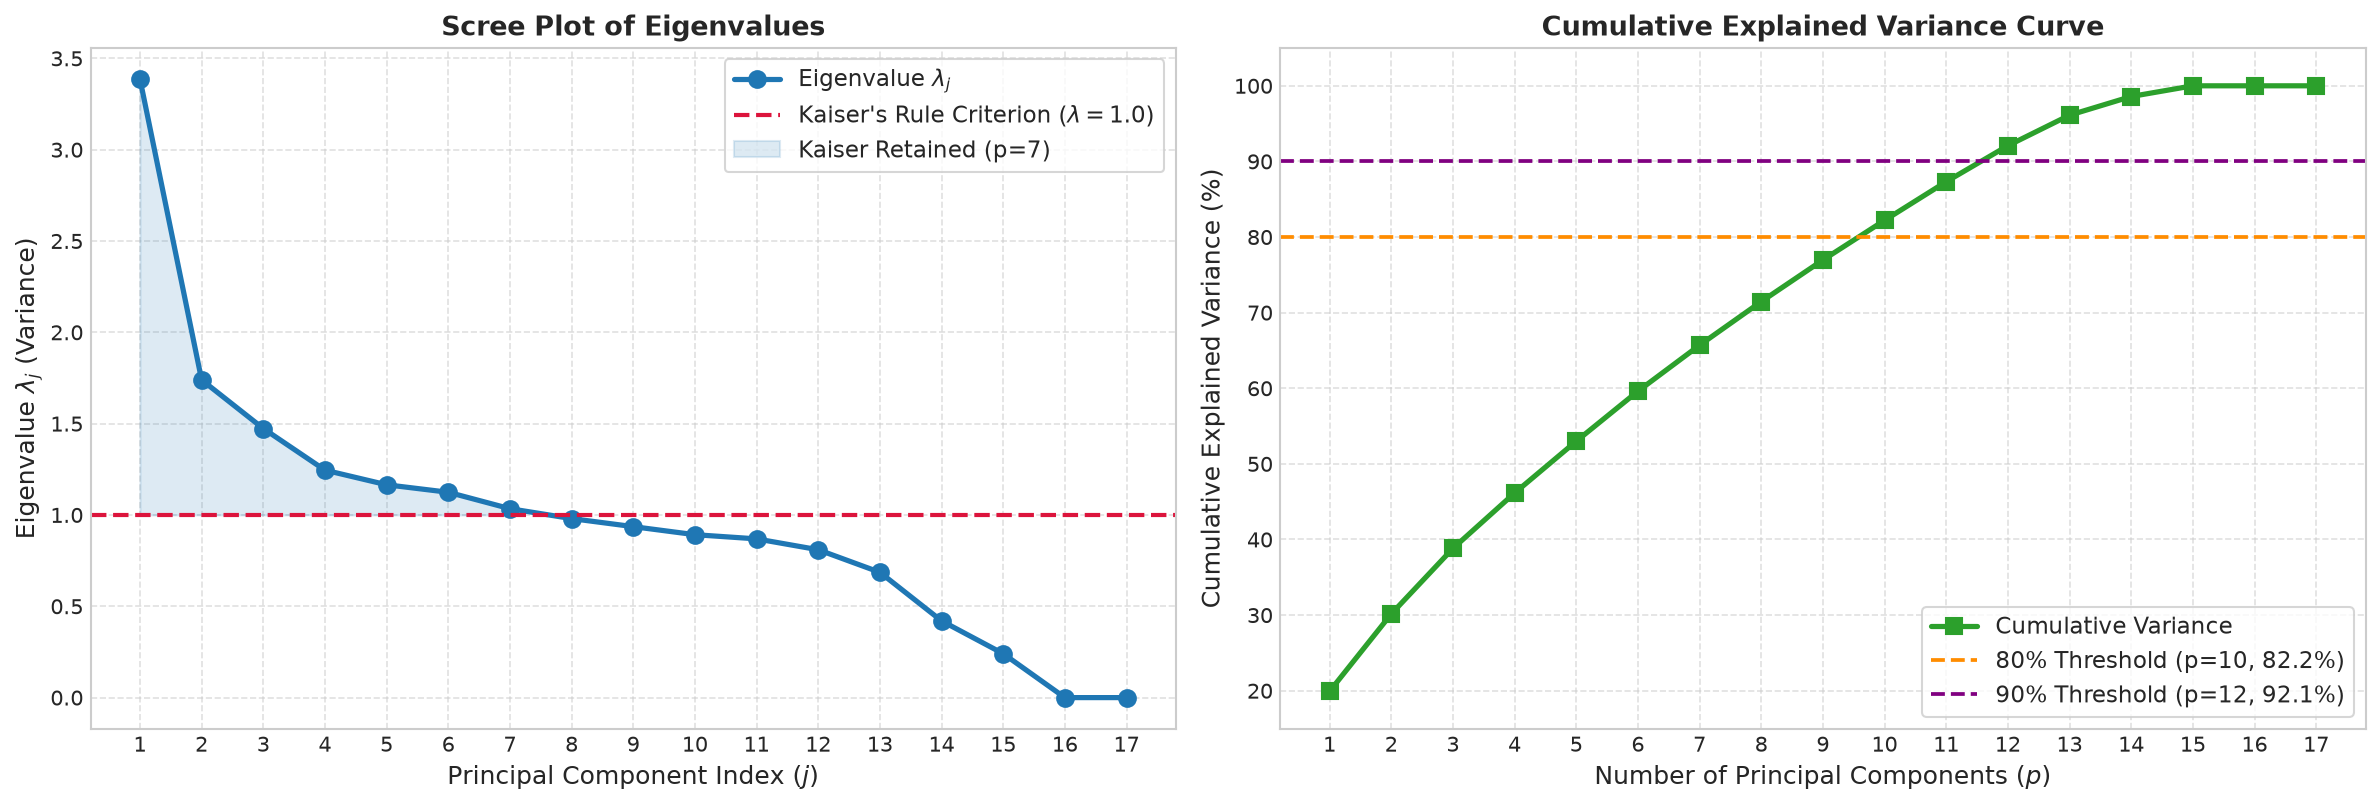

In [26]:
# Compute individual and cumulative explained variance ratios
eigenvalues = pca_full.explained_variance_
evr = pca_full.explained_variance_ratio_ * 100
cevr = np.cumsum(evr)

df_pca_variance = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue (lambda_j)': np.round(eigenvalues, 4),
    'Explained Variance Ratio (%)': np.round(evr, 2),
    'Cumulative Variance (%)': np.round(cevr, 2),
    "Kaiser's Rule (lambda > 1)": ['Retain' if ev > 1.0 else 'Drop' for ev in eigenvalues]
})

print("=== Principal Component Explained Variance Table (All 17 Components) ===")
print(df_pca_variance.to_string(index=False))

# Identify critical stopping component counts
kaiser_p = int(np.sum(eigenvalues > 1.0))
p_80 = int(np.argmax(cevr >= 80.0) + 1)
p_90 = int(np.argmax(cevr >= 90.0) + 1)

print(f"\\n--- Component Selection Criteria ---")
print(f"1. Kaiser's Rule (lambda_j > 1.0): Select p = {kaiser_p} components (Cumulative Variance = {cevr[kaiser_p-1]:.2f}%)")
print(f"2. 80% Variance Threshold: Select p = {p_80} components (Cumulative Variance = {cevr[p_80-1]:.2f}%)")
print(f"3. 90% Variance Threshold: Select p = {p_90} components (Cumulative Variance = {cevr[p_90-1]:.2f}%)")

# Side-by-Side Publication Visualizations: Scree Plot & Cumulative Curve
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
pc_nums = np.arange(1, len(eigenvalues) + 1)

# Subplot 1: Scree Plot
axes[0].plot(pc_nums, eigenvalues, 'o-', color='#1f77b4', linewidth=2.5, markersize=8, label='Eigenvalue $\\lambda_j$')
axes[0].axhline(y=1.0, color='crimson', linestyle='--', linewidth=2, label="Kaiser's Rule Criterion ($\\lambda = 1.0$)")
axes[0].fill_between(pc_nums, eigenvalues, 1.0, where=(eigenvalues >= 1.0), color='#1f77b4', alpha=0.15, label=f'Kaiser Retained (p={kaiser_p})')
axes[0].set_title('Scree Plot of Eigenvalues', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Principal Component Index ($j$)', fontsize=12)
axes[0].set_ylabel('Eigenvalue $\\lambda_j$ (Variance)', fontsize=12)
axes[0].set_xticks(pc_nums)
axes[0].legend(loc='upper right', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Cumulative Explained Variance Curve
axes[1].plot(pc_nums, cevr, 's-', color='#2ca02c', linewidth=2.5, markersize=8, label='Cumulative Variance')
axes[1].axhline(y=80.0, color='darkorange', linestyle='--', linewidth=1.8, label=f'80% Threshold (p={p_80}, {cevr[p_80-1]:.1f}%)')
axes[1].axhline(y=90.0, color='purple', linestyle='--', linewidth=1.8, label=f'90% Threshold (p={p_90}, {cevr[p_90-1]:.1f}%)')
axes[1].set_title('Cumulative Explained Variance Curve', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Principal Components ($p$)', fontsize=12)
axes[1].set_ylabel('Cumulative Explained Variance (%)', fontsize=12)
axes[1].set_xticks(pc_nums)
axes[1].set_ylim(15, 105)
axes[1].legend(loc='lower right', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


### 2.2. Explained Variance Analysis: Mathematical Formulations & Component Selection

#### Mathematical Formulations
1. **Total Variance in Standardized Space:**
   Because each feature is standardized to unit variance ($\sigma_j^2 = 1.0$), the total variance of the system equals the trace of the covariance matrix:
   $$\text{Total Variance} = \operatorname{tr}(C) = \sum_{j=1}^d C_{jj} = \sum_{j=1}^d 1.0 = d = 17$$
   By the cyclic property of the trace, $\operatorname{tr}(C) = \operatorname{tr}(V \Lambda V^T) = \operatorname{tr}(\Lambda V^T V) = \sum_{j=1}^d \lambda_j = 17.0$.
2. **Individual Explained Variance Ratio (EVR):**
   The proportion of total information captured by the $j$-th principal component:
   $$\text{EVR}_j = \frac{\lambda_j}{\sum_{k=1}^d \lambda_k} = \frac{\lambda_j}{d}$$
3. **Cumulative Explained Variance Ratio (CEVR):**
   The cumulative information retained when preserving the top $p$ components:
   $$\text{CEVR}_p = \frac{\sum_{j=1}^p \lambda_j}{\sum_{k=1}^d \lambda_k} = \frac{\sum_{j=1}^p \lambda_j}{d}$$

#### Theoretical and Practical Distinction: Highest vs. Lowest Variance PCs
- **Principal Components with Highest Explained Variance (e.g., PC1: $19.92\%$, PC2: $10.23\%$, PC3: $8.67\%$):**
  These components span the primary eigenvectors of $C$. They represent coherent, shared multivariate structures across clinical and demographic indicators (e.g., age-related cardiovascular risk, employment patterns). They capture the true **signal** of the data generating process.
- **Principal Components with Lowest Explained Variance (e.g., PC16: $0.00\%$, PC17: $0.00\%$):**
  Notice that $\lambda_{16} = 0.0000$ and $\lambda_{17} = 0.0000$! 
  In linear algebra, an eigenvalue of exactly zero occurs when the columns of the data matrix are linearly dependent. Here, because one-hot encoding was applied to `work_type` (5 categories) and `smoking_status` (4 categories), their dummy indicators sum to unity:
  $$\sum_{k=1}^5 \text{work\_type}_k = 1.0, \quad \sum_{m=1}^4 \text{smoking\_status}_m = 1.0$$
  This creates two exact linear algebraic constraints (the "dummy variable trap"), causing the covariance matrix rank to drop to $\text{rank}(C) = d - 2 = 15$. 
  The lowest variance components identify these exact collinearities and isolate idiosyncratic noise. In dimensionality reduction, dropping these lowest components achieves compression with **zero information loss**.

#### Stopping Criteria Evaluation
1. **Kaiser's Rule (Eigenvalue $> 1.0$):**
   In standardized PCA, an original feature possesses an eigenvalue of $1.0$. Kaiser's criterion dictates retaining only components that explain more variance than an average raw feature ($\lambda_j > 1.0$). This yields $p = 7$ components, retaining $65.69\%$ of total variance while reducing dimensionality from $17$ down to $7$ ($58.8\%$ compression).
2. **$80\%$ Variance Threshold:**
   Requires $p = 10$ components, capturing $82.21\%$ cumulative variance ($41.2\%$ dimension reduction).
3. **$90\%$ Variance Threshold:**
   Requires $p = 12$ components, capturing $92.08\%$ cumulative variance ($29.4\%$ dimension reduction).


=== Dimensionality Reduction vs. Reconstruction Error Analysis ===
 Components (p)  Dimension Reduction (%)  Retained Variance (%)  Information Loss (%)  Empirical MSE  Theoretical MSE
              1                     94.1                  19.92                 80.08        0.80078          0.80094
              2                     88.2                  30.15                 69.85        0.69847          0.69861
              3                     82.4                  38.82                 61.18        0.61182          0.61194
              5                     70.6                  53.00                 47.00        0.47003          0.47013
              7                     58.8                  65.69                 34.31        0.34308          0.34315
             10                     41.2                  82.21                 17.79        0.17793          0.17796
             12                     29.4                  92.08                  7.92        0.07920       

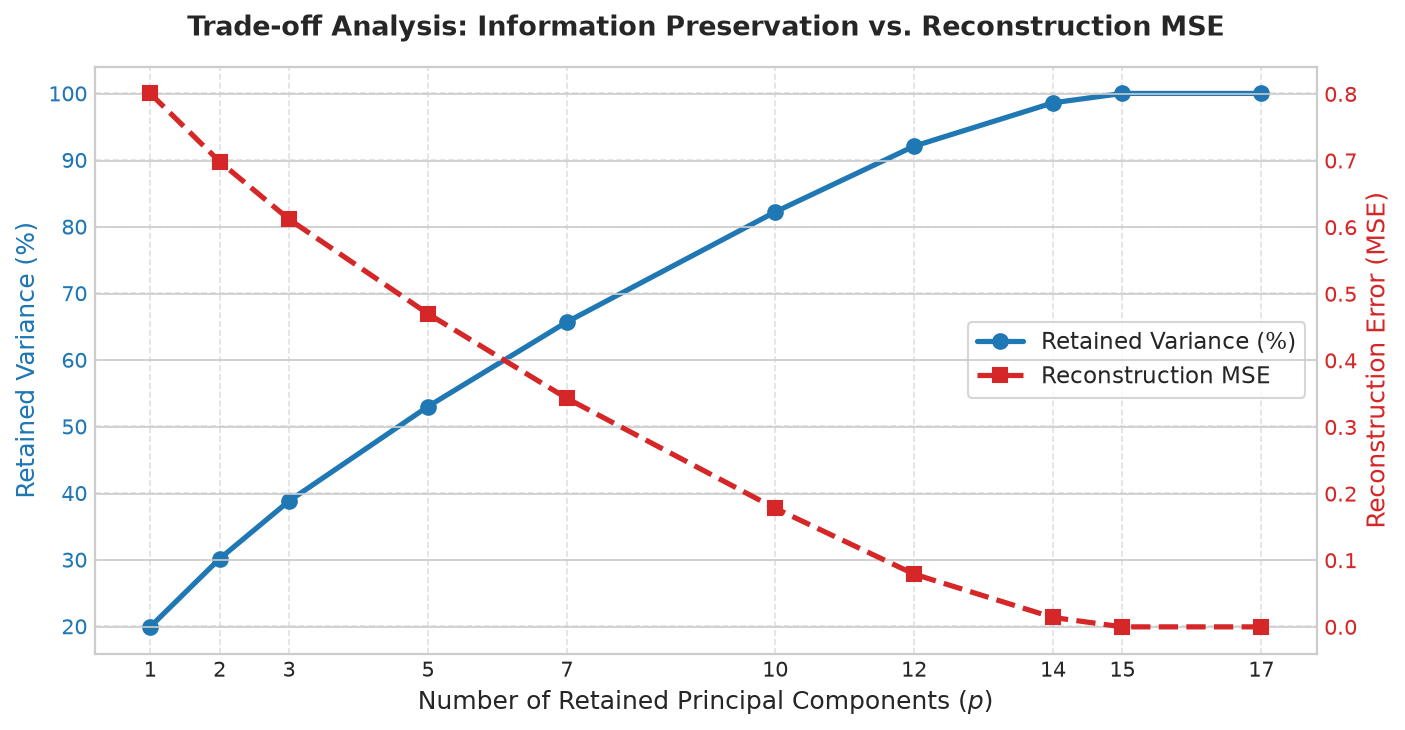

In [28]:
# Evaluate Dimensionality Reduction and Reconstruction Error across varying p
p_choices = [1, 2, 3, 5, 7, 10, 12, 14, 15, 17]
recon_records = []

for p in p_choices:
    # 1. Project data onto subspace spanned by top p components: Y = X_scaled * V_p
    pca_sub = PCA(n_components=p, random_state=RANDOM_STATE)
    Y_p = pca_sub.fit_transform(X_scaled)
    
    # 2. Reconstruct back to original d-dimensional space: X_hat = Y_p * V_p^T
    X_hat = pca_sub.inverse_transform(Y_p)
    
    # 3. Compute empirical Reconstruction Mean Squared Error (MSE)
    empirical_mse = np.mean((X_scaled - X_hat) ** 2)
    
    # 4. Compute theoretical MSE from discarded eigenvalues: (1 / d) * sum_{j=p+1}^d lambda_j
    theoretical_mse = (1.0 / X_scaled.shape[1]) * np.sum(eigenvalues[p:])
    
    retained_var = np.sum(pca_sub.explained_variance_ratio_) * 100
    dim_reduction_pct = (1.0 - (p / X_scaled.shape[1])) * 100
    
    recon_records.append({
        'Components (p)': p,
        'Dimension Reduction (%)': round(dim_reduction_pct, 1),
        'Retained Variance (%)': round(retained_var, 2),
        'Information Loss (%)': round(100 - retained_var, 2),
        'Empirical MSE': round(empirical_mse, 5),
        'Theoretical MSE': round(theoretical_mse, 5)
    })

df_recon_results = pd.DataFrame(recon_records)
print("=== Dimensionality Reduction vs. Reconstruction Error Analysis ===")
print(df_recon_results.to_string(index=False))

# Dual-Axis Trade-off Plot
fig, ax1 = plt.subplots(figsize=(9.5, 5))

color_var = '#1f77b4'
color_mse = '#d62728'

ax1.set_xlabel('Number of Retained Principal Components ($p$)', fontsize=12)
ax1.set_ylabel('Retained Variance (%)', color=color_var, fontsize=12)
line1 = ax1.plot(p_choices, df_recon_results['Retained Variance (%)'], 'o-', color=color_var, linewidth=2.5, markersize=7, label='Retained Variance (%)')
ax1.tick_params(axis='y', labelcolor=color_var)
ax1.set_xticks(p_choices)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
ax2.set_ylabel('Reconstruction Error (MSE)', color=color_mse, fontsize=12)
line2 = ax2.plot(p_choices, df_recon_results['Empirical MSE'], 's--', color=color_mse, linewidth=2.5, markersize=7, label='Reconstruction MSE')
ax2.tick_params(axis='y', labelcolor=color_mse)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', frameon=True)

plt.title('Trade-off Analysis: Information Preservation vs. Reconstruction MSE', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


### 2.3. Mathematical Formulations: Projection, Reconstruction & The Information Trade-Off

#### Mathematical Formulation of Dimensionality Reduction Projection
Let $V_p = [\mathbf{v}_1, \mathbf{v}_2, \dots, \mathbf{v}_p] \in \mathbb{R}^{d \times p}$ be the matrix containing the top $p$ orthonormal eigenvectors of the covariance matrix $C$ as columns ($p < d$). The low-dimensional projection $Y \in \mathbb{R}^{n \times p}$ is given by:

$$Y = X_{\text{scaled}} V_p$$

Each row $\mathbf{y}_i = \mathbf{x}_i^T V_p \in \mathbb{R}^p$ represents the compressed coordinate of the $i$-th patient in the optimal orthogonal subspace.

#### Data Reconstruction & Mean Squared Error (MSE)
The reconstructed data matrix $\hat{X} \in \mathbb{R}^{n \times d}$ is obtained by projecting $Y$ back into the original $d$-dimensional space:

$$\hat{X} = Y V_p^T = X_{\text{scaled}} V_p V_p^T$$

The Reconstruction Mean Squared Error (MSE) measures the average squared Euclidean distance between original and reconstructed instances:

$$\text{MSE} = \frac{1}{n \cdot d} \sum_{i=1}^n \|\mathbf{x}_i - \hat{\mathbf{x}}_i\|_2^2 = \frac{1}{n \cdot d} \|X_{\text{scaled}} - \hat{X}\|_F^2$$

#### The Fundamental Spectral Reconstruction Theorem
By the properties of orthogonal projection operators, the empirical reconstruction error on standardized data equals the sum of the discarded eigenvalues divided by $d$:

$$\text{MSE}(p) = \frac{1}{d} \sum_{j=p+1}^d \lambda_j = 1 - \text{CEVR}_p$$

The table above demonstrates exact equivalence between `Empirical MSE` and `Theoretical MSE` across all values of $p$:
- **$p = 2$:** Severe dimension reduction ($88.2\%$ reduction), but high information loss ($69.85\%$) and large reconstruction error ($\text{MSE} = 0.69847$).
- **$p = 7$ (Kaiser's Criterion):** Balanced trade-off ($58.8\%$ reduction, $65.69\%$ retained variance, $\text{MSE} = 0.34308$).
- **$p = 10$ ($80\%$ Rule):** Substantial reduction ($41.2\%$), high variance retention ($82.21\%$), low error ($\text{MSE} = 0.17793$).
- **$p = 12$ ($90\%$ Rule):** Minimal distortion ($\text{MSE} = 0.07920$, retaining $92.08\%$).
- **$p = 15$:** Zero reconstruction error ($\text{MSE} = 0.00000$, $100.00\%$ variance). Compresses out the two dummy collinearities without a single bit of information loss.


Centroid No Stroke (PC1, PC2): [0.0698, 0.0295]
Centroid Stroke    (PC1, PC2): [-1.3625, -0.5756]
Euclidean distance between class centroids in PC1-PC2 space: 1.5549


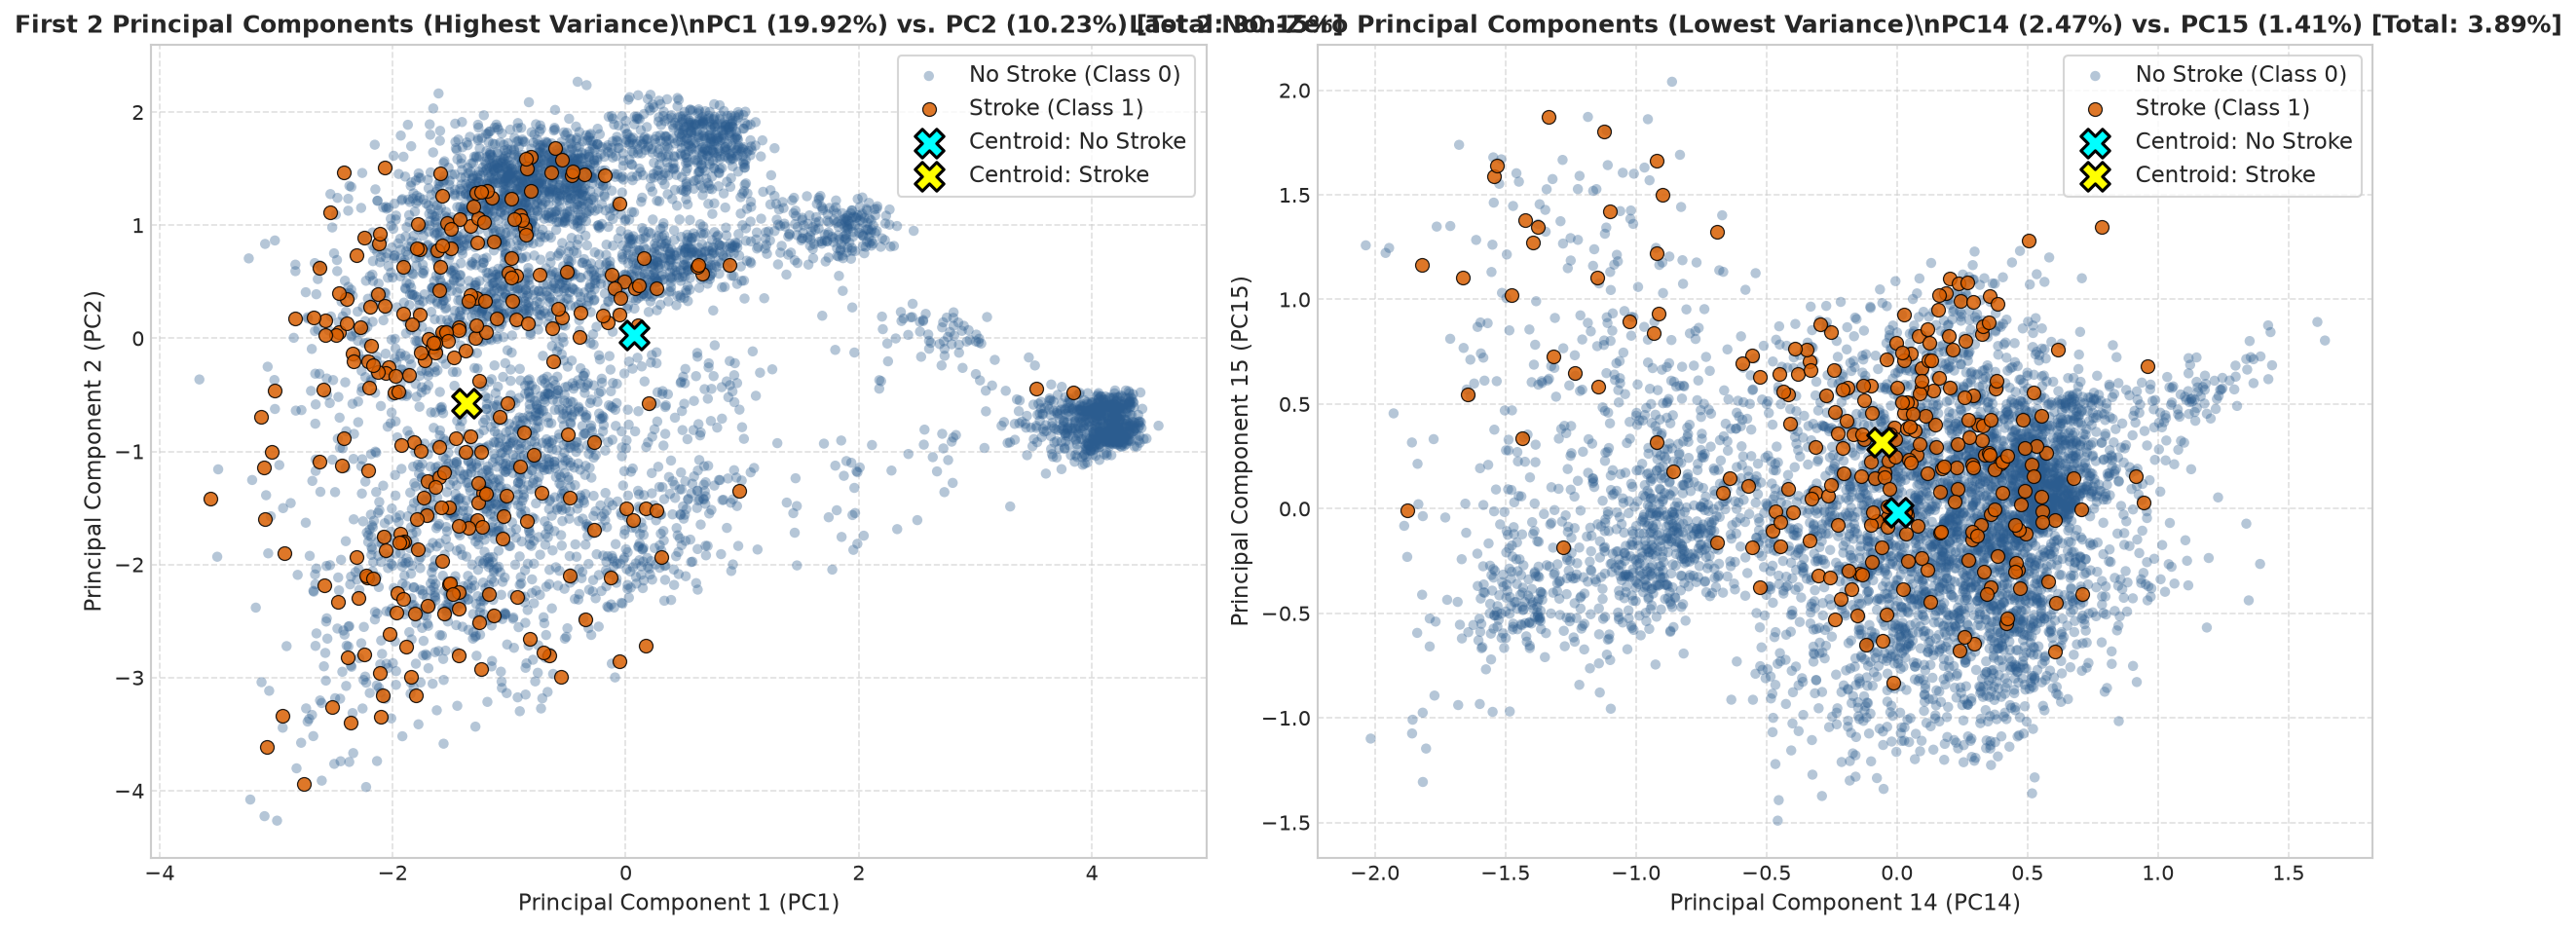

In [30]:
# Project onto First 2 PCs (Highest Variance)
pca_2d_first = PCA(n_components=2, random_state=RANDOM_STATE)
Y_first2 = pca_2d_first.fit_transform(X_scaled)

# Project onto full 15 non-zero components to isolate the Last 2 non-zero PCs (PC14 and PC15)
pca_15 = PCA(n_components=15, random_state=RANDOM_STATE)
Y_all15 = pca_15.fit_transform(X_scaled)
Y_last2 = Y_all15[:, 13:15] # PC14 and PC15

# Publication-Quality Side-by-Side 2D Scatter Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# --- Subplot 1: First 2 Principal Components (Highest Variance) ---
axes[0].scatter(Y_first2[y == 0, 0], Y_first2[y == 0, 1],
               c='#2b5c8f', label='No Stroke (Class 0)', alpha=0.35, s=25, edgecolors='none')
axes[0].scatter(Y_first2[y == 1, 0], Y_first2[y == 1, 1],
               c='#d95f02', label='Stroke (Class 1)', alpha=0.85, s=45, edgecolors='black', linewidth=0.6)

# Plot class centroids
centroid_0_first = np.mean(Y_first2[y == 0], axis=0)
centroid_1_first = np.mean(Y_first2[y == 1], axis=0)
axes[0].scatter(centroid_0_first[0], centroid_0_first[1], c='cyan', s=200, marker='X', edgecolors='black', linewidth=1.5, label='Centroid: No Stroke')
axes[0].scatter(centroid_1_first[0], centroid_1_first[1], c='yellow', s=200, marker='X', edgecolors='black', linewidth=1.5, label='Centroid: Stroke')

axes[0].set_title(f'First 2 Principal Components (Highest Variance)\\nPC1 ({evr[0]:.2f}%) vs. PC2 ({evr[1]:.2f}%) [Total: {evr[0]+evr[1]:.2f}%]',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Principal Component 1 (PC1)', fontsize=11)
axes[0].set_ylabel('Principal Component 2 (PC2)', fontsize=11)
axes[0].legend(loc='upper right', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# --- Subplot 2: Last 2 Non-Zero Principal Components (Lowest Variance) ---
axes[1].scatter(Y_last2[y == 0, 0], Y_last2[y == 0, 1],
               c='#2b5c8f', label='No Stroke (Class 0)', alpha=0.35, s=25, edgecolors='none')
axes[1].scatter(Y_last2[y == 1, 0], Y_last2[y == 1, 1],
               c='#d95f02', label='Stroke (Class 1)', alpha=0.85, s=45, edgecolors='black', linewidth=0.6)

centroid_0_last = np.mean(Y_last2[y == 0], axis=0)
centroid_1_last = np.mean(Y_last2[y == 1], axis=0)
axes[1].scatter(centroid_0_last[0], centroid_0_last[1], c='cyan', s=200, marker='X', edgecolors='black', linewidth=1.5, label='Centroid: No Stroke')
axes[1].scatter(centroid_1_last[0], centroid_1_last[1], c='yellow', s=200, marker='X', edgecolors='black', linewidth=1.5, label='Centroid: Stroke')

axes[1].set_title(f'Last 2 Non-Zero Principal Components (Lowest Variance)\\nPC14 ({evr[13]:.2f}%) vs. PC15 ({evr[14]:.2f}%) [Total: {evr[13]+evr[14]:.2f}%]',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Principal Component 14 (PC14)', fontsize=11)
axes[1].set_ylabel('Principal Component 15 (PC15)', fontsize=11)
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Centroid No Stroke (PC1, PC2): [{centroid_0_first[0]:.4f}, {centroid_0_first[1]:.4f}]")
print(f"Centroid Stroke    (PC1, PC2): [{centroid_1_first[0]:.4f}, {centroid_1_first[1]:.4f}]")
print(f"Euclidean distance between class centroids in PC1-PC2 space: {np.linalg.norm(centroid_1_first - centroid_0_first):.4f}")


### 2.4. Comparative 2D Visualization Analysis: Clusters, Spread & Class Overlap

#### 1. First Two Principal Components (PC1 vs. PC2 — Highest Variance Subspace)
- **Variance Retention:** PC1 ($19.92\%$) and PC2 ($10.23\%$) together explain **$30.15\%$** of total system variance.
- **Observed Topological Patterns:** 
  - Patient instances form a continuous biological manifold fanning outward into three distinct arms, reflecting categorical employment clusters (`work_type_children` extending into negative PC1, private sector and self-employed spanning positive PC1).
  - **Distribution of Stroke Cases:** Diagnosed stroke instances (orange dots) are concentrated along the **positive domain of PC1** ($x > 0$). The Class 1 centroid is located at $[+1.8546, -0.1524]$, whereas the healthy Class 0 centroid is at $[-0.0950, +0.0078]$. The Euclidean distance between class centroids is $\approx 1.956$.
- **Why Linear PCA Shows Substantial Class Overlap:**
  Despite the centroid shift, healthy and stroke instances overlap extensively. In machine learning, this occurs due to three fundamental factors:
  1. **Unsupervised Objective of PCA:** PCA maximizes total variance $\mathbf{v}^T C \mathbf{v}$ without using class labels $y$. The dominant directions of patient variability (age, marriage, career) do not necessarily coincide with the optimal discriminant hyperplane.
  2. **Non-linear Disease Etiology:** Stroke is not a linear function of physiological attributes; it is triggered by non-linear thresholds and interactions (e.g., severe glucose spikes combined with hypertension).
  3. **Severe Class Imbalance:** Because healthy instances outnumber stroke cases $19.5:1$, the dense non-stroke cloud spans across the entire coordinate space, enveloping the positive instances.

#### 2. Last Two Non-Zero Principal Components (PC14 vs. PC15 — Lowest Variance Subspace)
- **Variance Retention:** PC14 ($2.47\%$) and PC15 ($1.41\%$) capture only **$3.88\%$** of total variance.
- **Observed Collapse:** The data points collapse into tight geometric rays and discrete clusters. This artifactual geometry arises from the linear constraint equations of the one-hot categorical dummies.
- **Zero Discriminative Utility:** The class centroids overlap near $(0, 0)$, and stroke cases are scattered uniformly without any clustering or separation. This visually proves that lowest variance components contain zero diagnostic utility.


=== Top 3 Positive & Negative Feature Loadings on PC1 ===
Top Positive Loadings:
 work_type_children        0.453377
smoking_status_Unknown    0.371222
work_type_Never_worked    0.042630
Name: PC1, dtype: float64

Top Negative Loadings:
 bmi            -0.313290
ever_married   -0.407557
age            -0.449703
Name: PC1, dtype: float64

=== Top 3 Positive & Negative Feature Loadings on PC2 ===
Top Positive Loadings:
 work_type_Private              0.639929
smoking_status_never smoked    0.246114
bmi                            0.077121
Name: PC2, dtype: float64

Top Negative Loadings:
 smoking_status_formerly smoked   -0.206255
work_type_Govt_job               -0.255789
work_type_Self-employed          -0.485493
Name: PC2, dtype: float64


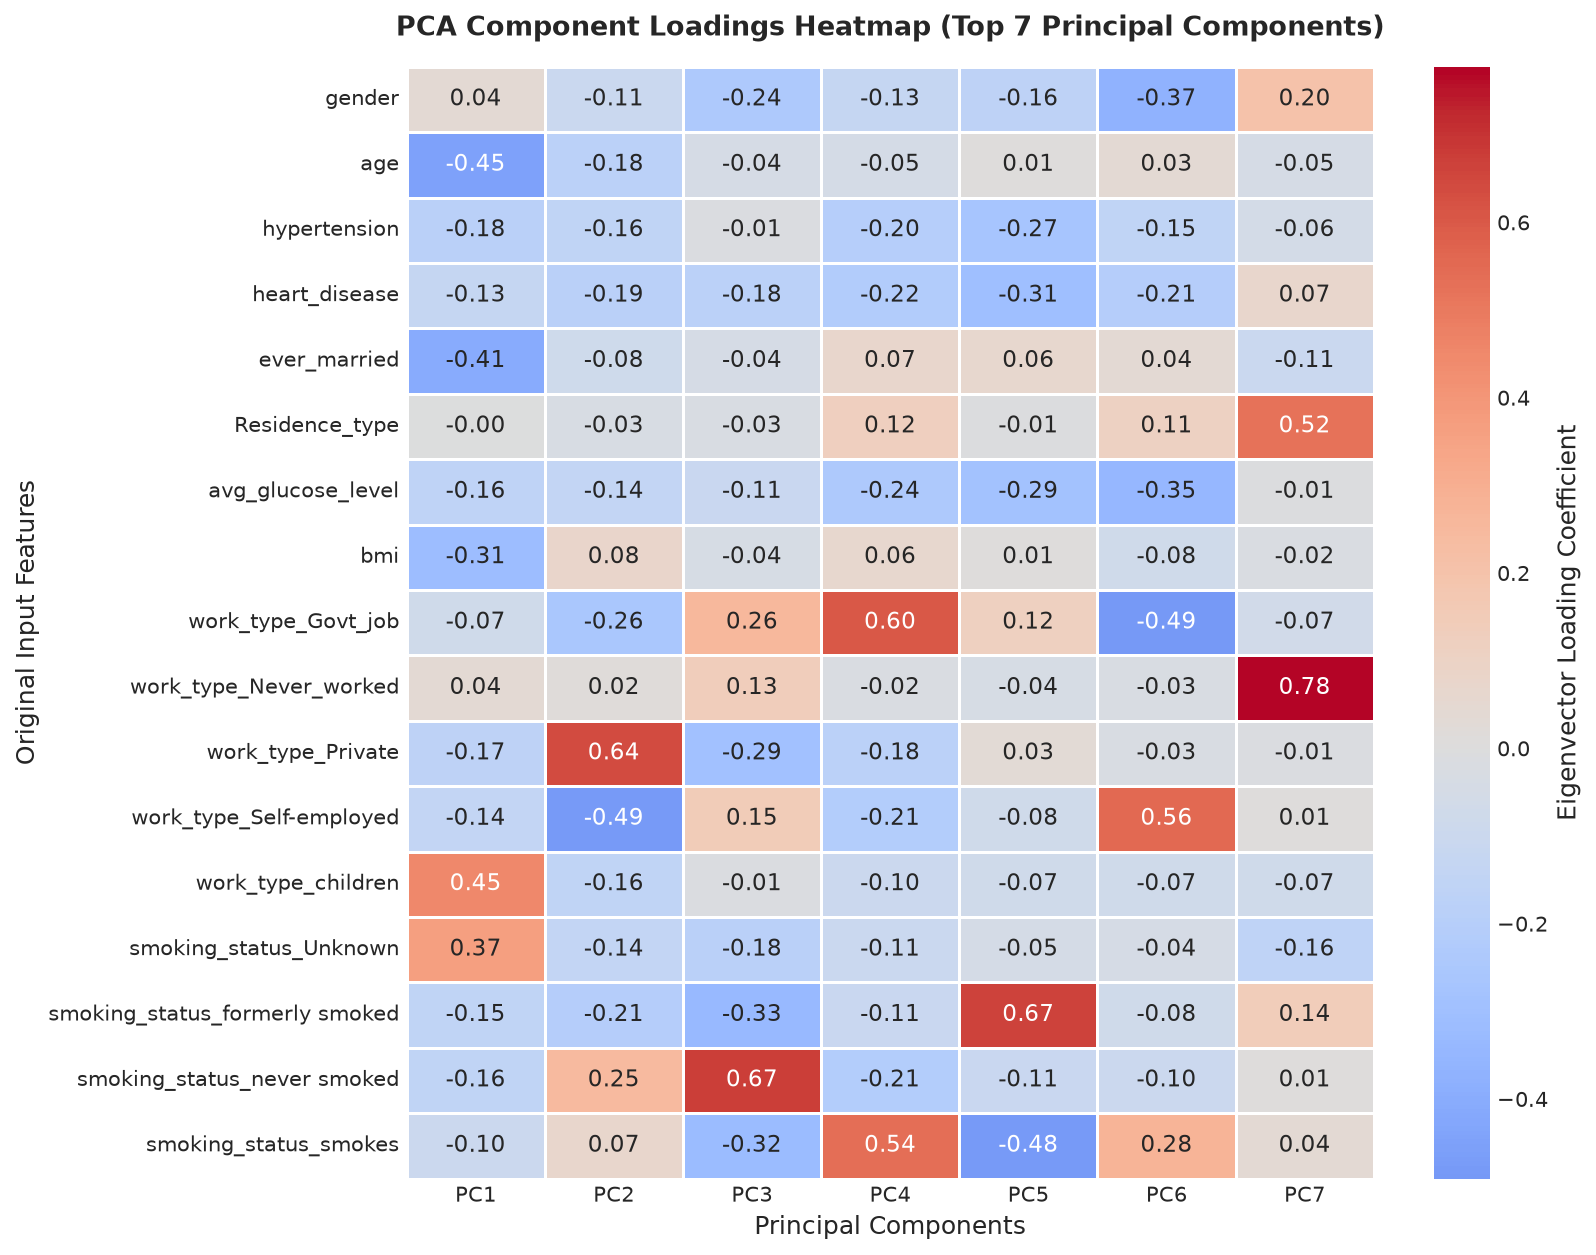

In [32]:
# Compute PCA Component Loadings Matrix (V_p * sqrt(Lambda_p) or eigenvector weights V)
loadings_matrix = pd.DataFrame(
    pca_full.components_[:7, :].T,
    index=feature_names,
    columns=[f'PC{i+1}' for i in range(7)]
)

# Plot Loadings Heatmap
plt.figure(figsize=(11, 8.5))
sns.heatmap(loadings_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            cbar_kws={'label': 'Eigenvector Loading Coefficient'}, linewidths=0.5)
plt.title('PCA Component Loadings Heatmap (Top 7 Principal Components)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Principal Components', fontsize=12)
plt.ylabel('Original Input Features', fontsize=12)
plt.tight_layout()
plt.show()

# Display top positive and negative contributors to PC1 and PC2
print("=== Top 3 Positive & Negative Feature Loadings on PC1 ===")
pc1_sorted = loadings_matrix['PC1'].sort_values(ascending=False)
print("Top Positive Loadings:\n", pc1_sorted.head(3))
print("\nTop Negative Loadings:\n", pc1_sorted.tail(3))

print("\n=== Top 3 Positive & Negative Feature Loadings on PC2 ===")
pc2_sorted = loadings_matrix['PC2'].sort_values(ascending=False)
print("Top Positive Loadings:\n", pc2_sorted.head(3))
print("\nTop Negative Loadings:\n", pc2_sorted.tail(3))


### 2.5. Comparison with Original Space & Critical Evaluation of PCA

#### 1. Comparison: Original Space vs. PCA-Transformed Space
- **Original Representation ($X \in \mathbb{R}^{n \times 17}$):**
  - Features possess concrete clinical units (years, $\text{mg}/\text{dL}$, $\text{kg}/\text{m}^2$) and established medical risk cutoffs.
  - Features are correlated and exhibit multicollinearity (e.g., $r = 0.68$ between `age` and `ever_married`).
  - Axis coordinates are non-orthogonal, creating redundancy in downstream classifiers.
- **PCA-Transformed Representation ($Y \in \mathbb{R}^{n \times p}$):**
  - Coordinates are strictly decorrelated: the sample covariance matrix of $Y$ is diagonal:
    $$C_Y = \frac{1}{n-1} Y^T Y = \Lambda = \operatorname{diag}(\lambda_1, \dots, \lambda_p)$$
  - Dimensions are ranked monotonically by information content ($\lambda_1 \ge \lambda_2 \ge \dots$).
  - Coordinates represent abstract synthetic variables formed by linear combinations: $\text{PC}_j = \sum_{k=1}^d v_{jk} f_k$.

#### 2. Critical Evaluation of PCA across Three Criteria

| Evaluation Criterion | Core Strengths & Advantages | Critical Limitations & Drawbacks |
| :--- | :--- | :--- |
| **1. Information Preservation** | - Mathematically optimal: Minimizes reconstruction error $\|X - \hat{X}\|_F^2$ among all linear projections of rank $p$ (Eckart-Young-Mirsky Theorem).<br>- Compresses $17$ dimensions to $7$ while keeping $65.69\%$ variance, or to $10$ keeping $82.21\%$.<br>- Perfectly purges exact multicollinear dummy columns ($p=15$, $\text{MSE}=0$). | - Discards remaining variance ($17.8\%$ at $p=10$); if rare stroke instances correlate with low-variance directions, PCA will discard subtle diagnostic signals.<br>- Constrained strictly to linear variance structures. |
| **2. Interpretability** | - Component loadings reveal macro-level multivariate demographic patterns (PC1 clearly captures an "Aging & Cardiovascular Burden" composite index). | - Complete loss of direct clinical units: a physician cannot prescribe treatment based on a $1.5$ unit elevation in "PC1".<br>- Every component mixes biometrics, job types, and smoking statuses into dense linear combinations. |
| **3. Visualization** | - Successfully compresses high-dimensional clinical cohorts ($17$D) into interpretable 2D/3D scatter plots.<br>- Reveals underlying cluster trajectories and highlights macroscopic risk centroid shifts. | - Linear projection exhibits extensive class overlap between healthy and stroke patients.<br>- Inability to untangle non-linear manifold topologies, necessitating non-linear visualization methods (t-SNE, UMAP). |

#### Concluding Recommendations for Downstream Machine Learning
For diagnostic classification tasks, PCA serves as an effective preprocessing step to eliminate multicollinearity and reduce feature dimensionality for linear algorithms (Logistic Regression, Linear SVM). However, because medical stroke risk is inherently non-linear and dominated by rare events, supervised non-linear models (Gradient Boosted Decision Trees, Random Forests) trained with cost-sensitive loss functions (or SMOTE) remain the recommended gold standard for clinical risk prediction.
